In [2]:
pip install ucimlrepo

In [3]:

from ucimlrepo import fetch_ucirepo

# fetch dataset
phiusiil_phishing_url_website = fetch_ucirepo(id=967)

# data (as pandas dataframes)
x = phiusiil_phishing_url_website.data.features
y = phiusiil_phishing_url_website.data.targets

# metadata
print(phiusiil_phishing_url_website.metadata)

# variable information
print(phiusiil_phishing_url_website.variables)


{'uci_id': 967, 'name': 'PhiUSIIL Phishing URL (Website)', 'repository_url': 'https://archive.ics.uci.edu/dataset/967/phiusiil+phishing+url+dataset', 'data_url': 'https://archive.ics.uci.edu/static/public/967/data.csv', 'abstract': 'PhiUSIIL Phishing URL Dataset is a substantial dataset comprising 134,850 legitimate and 100,945 phishing URLs. Most of the URLs we analyzed, while constructing the dataset, are the latest URLs. Features are extracted from the source code of the webpage and URL. Features such as CharContinuationRate, URLTitleMatchScore, URLCharProb, and TLDLegitimateProb are derived from existing features.', 'area': 'Computer Science', 'tasks': ['Classification'], 'characteristics': ['Tabular'], 'num_instances': 235795, 'num_features': 54, 'feature_types': ['Real', 'Categorical', 'Integer'], 'demographics': [], 'target_col': ['label'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2024, 'last_updated': 'Sun May 12 

In [4]:
y.value_counts(normalize=True)

,proportion
label,
1,0.571895
0,0.428105


In [5]:
print(x.shape) #we got 54 explicative variables
print(y.shape) #we got 1 target

(235795, 54)
(235795, 1)


In [6]:
print("Nombre de lignes :", x.shape[0])
print("Nombre de features :", x.shape[1])
print("les types : ",x.dtypes.value_counts()) #type
#valeurs manquantes we know we got none
print(" valeurs manquantes de x : ", x.isnull().sum().sum())
print("valeurs manquantes de y : ", y.isnull().sum().sum())
#doublons
print("x :", x.duplicated().sum())
print("\n DISTRIBUTION DE LA CIBLE :")
print(y["label"].value_counts())
print(y["label"].value_counts(normalize=True))
print("\n===== VALEURS UNIQUES =====")
for col in x.columns:
    print(f"{col:35} | type = {x[col].dtype} | uniques = {x[col].nunique()}")

Nombre de lignes : 235795
Nombre de features : 54
les types :  int64      40
float64    10
object      4
Name: count, dtype: int64
 valeurs manquantes de x :  0
valeurs manquantes de y :  0
x : 0

 DISTRIBUTION DE LA CIBLE :
label
1    134850
0    100945
Name: count, dtype: int64
label
1    0.571895
0    0.428105
Name: proportion, dtype: float64

===== VALEURS UNIQUES =====
URL                                 | type = object | uniques = 235370
URLLength                           | type = int64 | uniques = 482
Domain                              | type = object | uniques = 220086
DomainLength                        | type = int64 | uniques = 101
IsDomainIP                          | type = int64 | uniques = 2
TLD                                 | type = object | uniques = 695
URLSimilarityIndex                  | type = float64 | uniques = 36360
CharContinuationRate                | type = float64 | uniques = 898
TLDLegitimateProb                   | type = float64 | uniques = 465
URLCh

In [7]:
print(x.describe().T)

                               count          mean            std        min  \
URLLength                   235795.0     34.573095      41.314153  13.000000   
DomainLength                235795.0     21.470396       9.150793   4.000000   
IsDomainIP                  235795.0      0.002706       0.051946   0.000000   
URLSimilarityIndex          235795.0     78.430778      28.976055   0.155574   
CharContinuationRate        235795.0      0.845508       0.216632   0.000000   
TLDLegitimateProb           235795.0      0.260423       0.251628   0.000000   
URLCharProb                 235795.0      0.055747       0.010587   0.001083   
TLDLength                   235795.0      2.764456       0.599739   2.000000   
NoOfSubDomain               235795.0      1.164758       0.600969   0.000000   
HasObfuscation              235795.0      0.002057       0.045306   0.000000   
NoOfObfuscatedChar          235795.0      0.024861       1.876249   0.000000   
ObfuscationRatio            235795.0    

## 📝 Observations principales de `describe().T`

L'analyse statistique permet d'identifier plusieurs caractéristiques importantes
dans les données.

### 1. `URLLength`

- Moyenne : **34.57**
- Médiane : **27**
- 75% des valeurs : **34**
- Maximum : **6097**

La moyenne est supérieure à la médiane et la valeur maximale est très élevée.
Cela indique une **forte asymétrie à droite** (*right-skewed distribution*) avec
des valeurs extrêmes.

Ces valeurs élevées peuvent correspondre à des URLs particulièrement longues.
Il ne faut pas supprimer automatiquement ces observations car la longueur
d'une URL peut constituer un **signal important pour détecter le phishing**.

### 2. `DomainLength`

- Moyenne : **21.47**
- Médiane : **20**
- Maximum : **110**

La distribution est moins extrême que celle de `URLLength`, mais certaines URLs
possèdent des domaines beaucoup plus longs que la majorité des observations.

### 3. `URLSimilarityIndex`

La médiane et le troisième quartile sont tous les deux égaux à **100**.

Cela montre que beaucoup d'observations sont concentrées autour de la valeur
maximale. Cette variable présente donc une distribution particulière et devra
être examinée plus précisément.

### 4. `TLDLegitimateProb`
Cette variable représente une probabilité liée au caractère légitime du
TLD (*Top-Level Domain*).

D'après `describe()` :

- 25% des valeurs sont inférieures ou égales à `0.006`
- 50% des valeurs sont inférieures ou égales à `0.080`
- 75% des valeurs sont inférieures ou égales à `0.523`
- maximum = `0.523`

La moitié des observations possède donc une valeur inférieure ou égale à
`0.080`. Les valeurs sont ainsi fortement concentrées dans les faibles
valeurs.

Cependant, cette analyse ne permet pas encore de savoir si cette variable
permet de distinguer les URLs phishing des URLs légitimes. Nous comparerons
sa distribution selon la variable cible `label`.

### 5. Variables binaires

Plusieurs variables sont codées en **0/1**, par exemple :

- `IsDomainIP`
- `HasObfuscation`
- `IsHTTPS`
- `HasTitle`
- `HasFavicon`
- `Robots`
- `Bank`
- `Pay`
- `Crypto`
- `HasPasswordField`

Pour ces variables, la moyenne représente directement la **proportion de
valeurs égales à 1**.

Par exemple, `IsDomainIP` a une moyenne de **0.0027**, ce qui signifie qu'environ
**0.27 %** des URLs utilisent directement une adresse IP comme domaine.

Certaines variables binaires sont donc très rares, mais cela ne signifie pas
qu'elles sont inutiles : une caractéristique rare peut être particulièrement
discriminante pour détecter une URL de phishing.

### 6. Variables de comptage avec forte asymétrie

Certaines variables présentent des valeurs maximales très élevées par rapport
à leur médiane :

- `LineOfCode` : médiane = **429**, maximum ≈ **442 666**
- `LargestLineLength` : médiane = **1 090**, maximum ≈ **13.98 millions**
- `NoOfImage` : médiane = **8**, maximum = **8 956**
- `NoOfCSS` : médiane = **2**, maximum = **35 820**
- `NoOfJS` : médiane = **6**, maximum = **6 957**
- `NoOfSelfRef` : médiane = **12**, maximum = **27 397**
- `NoOfExternalRef` : médiane = **10**, maximum = **27 516**

Ces variables sont fortement **asymétriques** et contiennent des valeurs
extrêmes.

Il faudra éventuellement étudier des transformations comme `log1p` lors de la
phase de préparation, mais aucune transformation ne sera appliquée
automatiquement à ce stade.

### 7. Différences d'échelle

Les variables numériques ont des échelles très différentes.

Par exemple :

- `URLCharProb` varie autour de **0 à 0.09**
- `URLLength` peut atteindre **6097**
- `LineOfCode` peut atteindre plusieurs centaines de milliers
- `LargestLineLength` peut atteindre plusieurs millions

Cette différence d'échelle devra être prise en compte pour certains modèles,
notamment **Logistic Regression** et **KNN**.

Le scaling sera réalisé plus tard dans le pipeline de prétraitement afin
d'éviter toute fuite de données (*data leakage*).

### Conclusion

L'analyse de `describe().T` montre principalement :

- des **distributions asymétriques** pour plusieurs variables ;
- des **valeurs extrêmes** dans certaines variables de comptage ;
- des **variables binaires parfois très rares** ;
- des **échelles très différentes** entre les features.

Ces observations seront prises en compte lors de la phase de préparation et
de modélisation.

In [8]:
data = x.copy()
data["label"] = y["label"]
comparison = data.groupby("label").mean(numeric_only=True).T
print(comparison)

label                                  0            1
URLLength                      45.720293    26.228610
DomainLength                   24.465144    19.228610
IsDomainIP                      0.006320     0.000000
URLSimilarityIndex             49.616973   100.000000
CharContinuationRate            0.728395     0.933176
TLDLegitimateProb               0.232099     0.281625
URLCharProb                     0.049999     0.060050
TLDLength                       2.819327     2.723382
NoOfSubDomain                   1.168894     1.161661
HasObfuscation                  0.004805     0.000000
NoOfObfuscatedChar              0.058071     0.000000
ObfuscationRatio                0.000323     0.000000
NoOfLettersInURL               28.106583    12.933059
LetterRatioInURL                0.568366     0.476705
NoOfDegitsInURL                 4.326217     0.050597
DegitRatioInURL                 0.064018     0.002115
NoOfEqualsInURL                 0.145386     0.000000
NoOfQMarkInURL              

### `URLLength`

La longueur moyenne des URLs est de **45.72** pour les URLs phishing
contre **26.23** pour les URLs légitimes.

Les URLs phishing sont donc en moyenne plus longues.
Cette variable semble potentiellement discriminante entre les deux classes.
### `DomainLength`

La longueur moyenne du domaine est de **24.47** pour les URLs phishing
contre **19.23** pour les URLs légitimes.

On observe une différence entre les deux classes, mais elle est moins
marquée que pour `URLLength`.

### `IsDomainIP`

`IsDomainIP` est une variable binaire :

- `1` → le domaine est une adresse IP ;
- `0` → le domaine n'est pas une adresse IP.

Il ne faut pas confondre cette variable avec la variable cible `label` :

- `label = 0` → URL phishing ;
- `label = 1` → URL légitime.

Pour les URLs phishing, la moyenne de `IsDomainIP` est de `0.006320` :

\[
0.006320 \times 100 = 0.632\%
\]

Cela signifie que **0.632 % des URLs phishing utilisent une adresse IP comme domaine**, tandis que **99.368 % n'utilisent pas d'adresse IP**.

Pour les URLs légitimes, la moyenne est de `0.000000`, ce qui signifie que **0 % utilisent une adresse IP comme domaine** et que **100 % n'en utilisent pas**.

On observe donc que l'utilisation d'une adresse IP comme domaine est très rare dans le dataset, mais qu'elle apparaît uniquement dans la classe phishing. Cette caractéristique peut donc être intéressante pour la classification.
### `HasObfuscation`

`HasObfuscation` est une variable binaire indiquant la présence d'une
obfuscation dans l'URL.

La moyenne de `HasObfuscation` est de **0.0048** pour les URLs phishing
contre **0** pour les URLs légitimes.

Comme cette variable est binaire (`0/1`), sa moyenne peut être interprétée
comme une proportion.

Pour les URLs phishing :

\[
0.0048 \times 100 = 0.48\%
\]

Cela signifie que **0.48 % des URLs phishing présentent une obfuscation**.

Pour les URLs légitimes, la moyenne est de **0**, ce qui signifie que
**0 % des URLs légitimes présentent une obfuscation**.

L'obfuscation est donc très rare dans l'ensemble du dataset, mais elle apparaît
uniquement dans la classe phishing. Cette caractéristique peut donc être
intéressante pour la classification.
### `URLSimilarityIndex`

La moyenne de `URLSimilarityIndex` est de **49.62** pour les URLs phishing
contre **100.00** pour les URLs légitimes.

On observe une différence très importante entre les deux classes. Les URLs
légitimes présentent en moyenne un indice de similarité beaucoup plus élevé
que les URLs phishing.

Cette variable semble donc potentiellement **très discriminante** pour la
classification.
### `CharContinuationRate`

`CharContinuationRate` est un ratio compris entre 0 et 1 qui représente le taux
de continuation des caractères dans l'URL.

La moyenne est de **0.7284** pour les URLs phishing contre **0.9332** pour les
URLs légitimes.

Comme cette variable est un ratio, ces valeurs correspondent respectivement
à environ **72.84 %** et **93.32 %**.

Les URLs légitimes présentent donc en moyenne un taux de continuation des
caractères plus élevé que les URLs phishing.

On observe une différence importante entre les deux classes. Cette variable
semble donc potentiellement discriminante pour la classification.
### `TLDLegitimateProb`

`TLDLegitimateProb` représente une probabilité associée à la légitimité du
TLD.

La moyenne est de **0.2321** pour les URLs phishing contre **0.2816** pour les
URLs légitimes.

Comme cette variable est une probabilité comprise entre 0 et 1, ces valeurs
correspondent respectivement à environ **23.21 %** et **28.16 %**.

On observe une différence entre les deux classes, mais elle reste relativement
faible par rapport à d'autres variables du dataset.

Cette variable pourrait donc apporter une information complémentaire, mais
elle semble moins discriminante à première vue.### `URLCharProb`

`URLCharProb` représente une probabilité associée aux caractères présents dans
l'URL.

La moyenne est de **0.04999** pour les URLs phishing contre **0.06005** pour les
URLs légitimes.

Comme cette variable est comprise entre 0 et 1, ces valeurs correspondent
respectivement à environ **4.999 %** et **6.005 %**.

On observe une légère différence entre les deux classes. Cette variable semble
donc moins discriminante à première vue, mais elle peut tout de même apporter
une information complémentaire au modèle.
### `TLDLength`

La moyenne de `TLDLength` est de **2.82** pour les URLs phishing contre
**2.72** pour les URLs légitimes.

La différence entre les deux classes est très faible. Cette variable semble
donc **peu discriminante** à première vue.
### `NoOfSubDomain`
`NoOfSubDomain` représente le nombre de sous-domaines présents dans l'URL.
La moyenne est de **1.17** pour les URLs phishing contre **1.16** pour les
URLs légitimes.
La différence est très faible. Cette variable semble donc peu discriminante
à première vue.

###`NoOfObfuscatedChar`
`NoOfObfuscatedChar` représente le nombre de caractères obfusqués présents
dans l'URL.
La moyenne est de **0.058** pour les URLs phishing contre **0** pour les URLs
légitimes.
Les URLs phishing contiennent donc en moyenne davantage de caractères
obfusqués.
La différence reste faible en valeur absolue, mais cette variable est
cohérente avec `HasObfuscation` et peut apporter une information
complémentaire.

###`ObfuscationRatio`

`ObfuscationRatio` représente la proportion de caractères obfusqués dans
l'URL.

La moyenne est de **0.000323** pour les URLs phishing contre **0** pour les
URLs légitimes.

Comme il s'agit d'un ratio, cela correspond à environ **0.0323 %** pour les
URLs phishing contre **0 %** pour les URLs légitimes.

L'obfuscation reste donc très rare dans le dataset, mais cette caractéristique
est davantage présente dans la classe phishing.
###`NoOfLettersInURL`

`NoOfLettersInURL` représente le nombre de lettres présentes dans l'URL.

La moyenne est de **28.11** pour les URLs phishing contre **12.93** pour les
URLs légitimes.

Les URLs phishing contiennent donc en moyenne **beaucoup plus de lettres**.

La différence entre les deux classes est importante. Cette variable semble
donc **potentiellement fortement** discriminante.
### `LetterRatioInURL`

`LetterRatioInURL` représente la **proportion de lettres présentes dans l'URL**.

La moyenne est de **0.568** pour les URLs phishing contre **0.477** pour les URLs légitimes.

Cela correspond respectivement à environ **56.8 %** et **47.7 %**.

On observe une différence entre les deux classes, mais elle est moins marquée que celle observée pour `NoOfLettersInURL`.
### `NoOfDegitsInURL`

`NoOfDegitsInURL` représente le **nombre de chiffres présents dans l'URL**.

La moyenne est de **4.33** pour les URLs phishing contre **0.05** pour les URLs légitimes.

Les URLs phishing contiennent donc en moyenne beaucoup plus de chiffres.

La différence est très importante entre les deux classes. Cette variable semble donc **très discriminante** à première vue.

### `DegitRatioInURL`

`DegitRatioInURL` représente la **proportion de chiffres présents dans l'URL**.

La moyenne est de **0.064** pour les URLs phishing contre **0.002** pour les URLs légitimes.

Cela correspond respectivement à environ **6.4 %** et **0.2 %**.

Les URLs phishing présentent donc une proportion de chiffres nettement plus élevée. Cette variable semble également **potentiellement très discriminante**.

### `NoOfEqualsInURL`

`NoOfEqualsInURL` représente le **nombre de caractères `=` présents dans l'URL**.

La moyenne est de **0.145** pour les URLs phishing contre **0** pour les URLs légitimes.

Les URLs phishing contiennent donc en moyenne davantage de caractères `=`.

La différence est notable, cette variable peut donc être **potentiellement discriminante** pour la classification.

### `NoOfQMarkInURL`

`NoOfQMarkInURL` représente le **nombre de caractères `?` présents dans l'URL**.

La moyenne est de **0.069** pour les URLs phishing contre **0** pour les URLs légitimes.

Les URLs phishing présentent donc davantage de caractères `?` en moyenne.

Cette différence peut rendre cette variable **potentiellement intéressante** pour la classification.

### `NoOfAmpersandInURL`

`NoOfAmpersandInURL` représente le **nombre de caractères `&` présents dans l'URL**.

La moyenne est de **0.059** pour les URLs phishing contre **0** pour les URLs légitimes.

Les URLs phishing contiennent donc en moyenne davantage de caractères `&`.

Cette différence peut apporter une information utile pour distinguer les deux classes.

### `NoOfOtherSpecialCharsInURL`

`NoOfOtherSpecialCharsInURL` représente le **nombre d'autres caractères spéciaux présents dans l'URL**.

La moyenne est de **3.80** pour les URLs phishing contre **1.24** pour les URLs légitimes.

Les URLs phishing contiennent donc en moyenne davantage de caractères spéciaux.

La différence entre les deux classes est importante. Cette variable semble donc **potentiellement discriminante**.

### `SpacialCharRatioInURL`

`SpacialCharRatioInURL` représente la **proportion de caractères spéciaux présents dans l'URL**.

La moyenne est de **0.083** pour les URLs phishing contre **0.048** pour les URLs légitimes.

Cela correspond respectivement à environ **8.3 %** et **4.8 %**.

Les URLs phishing présentent donc une proportion de caractères spéciaux plus élevée.

Cette différence peut rendre cette variable **potentiellement discriminante**.

### `IsHTTPS`

`IsHTTPS` est une variable binaire indiquant si l'URL utilise le protocole HTTPS.

La moyenne est de **0.492** pour les URLs phishing contre **1.000** pour les URLs légitimes.

Comme cette variable est binaire, cela correspond à environ **49.2 %** des URLs phishing utilisant HTTPS contre **100 %** des URLs légitimes.

On observe une différence très importante entre les deux classes. Cette variable semble donc **très discriminante** dans ce dataset.

Cependant, l'utilisation de HTTPS ne garantit pas à elle seule qu'un site est légitime. Il s'agit ici d'une observation propre à ce dataset.

### `LineOfCode`

`LineOfCode` représente le **nombre de lignes de code présentes dans la page web**.

La moyenne est de **65.73** pour les URLs phishing contre **1947.49** pour les URLs légitimes.

Les pages associées aux URLs légitimes contiennent donc en moyenne beaucoup plus de lignes de code.

La différence entre les deux classes est très importante. Cette variable semble donc **potentiellement très discriminante**.

### `LargestLineLength`

`LargestLineLength` représente la **longueur de la plus grande ligne de code de la page**.

La moyenne est de **20021.45** pour les URLs phishing contre **7375.92** pour les URLs légitimes.

Contrairement à `LineOfCode`, les pages phishing présentent ici une longueur maximale de ligne plus élevée en moyenne.

La différence entre les deux classes est importante. Cette variable semble donc **potentiellement discriminante**.
### `HasTitle`

`HasTitle` est une variable binaire indiquant si la page web possède un titre HTML.

La moyenne est de **0.678** pour les URLs phishing contre **0.999** pour les URLs légitimes.

Comme cette variable est binaire, cela correspond à environ **67.8 %** des pages phishing ayant un titre contre **99.9 %** des pages légitimes.

La différence entre les deux classes est importante. Cette variable semble donc **potentiellement discriminante** pour la classification.

### `Title`

`Title` représente le **titre de la page web**.

Il s'agit d'une variable textuelle avec un très grand nombre de valeurs différentes (**197 874 valeurs uniques**).

Il n'est donc pas pertinent de comparer directement les moyennes de cette variable.

Cette variable pourrait contenir des informations utiles, mais son traitement nécessite une approche spécifique pour les données textuelles. Une transformation ou une extraction de caractéristiques pourrait être envisagée, plutôt que de l'utiliser directement comme une variable catégorielle classique.

### `DomainTitleMatchScore`

`DomainTitleMatchScore` représente le **degré de correspondance entre le domaine et le titre de la page**.

La moyenne est de **16.55** pour les URLs phishing contre **75.27** pour les URLs légitimes.

Les pages légitimes présentent donc en moyenne une correspondance beaucoup plus élevée entre leur domaine et leur titre.

La différence entre les deux classes est très importante. Cette variable semble donc **potentiellement très discriminante**.

### `URLTitleMatchScore`

`URLTitleMatchScore` représente le **degré de correspondance entre l'URL et le titre de la page**.

La moyenne est de **21.20** pour les URLs phishing contre **75.27** pour les URLs légitimes.

Les URLs légitimes présentent donc en moyenne une correspondance beaucoup plus importante entre l'URL et le titre de la page.

La différence entre les deux classes est importante. Cette variable semble donc **potentiellement très discriminante**.

### `HasFavicon`

`HasFavicon` est une variable binaire indiquant si la page possède une **icône de site (favicon)**.

La moyenne est de **0.088** pour les URLs phishing contre **0.567** pour les URLs légitimes.

Comme cette variable est binaire, cela correspond à environ **8.8 %** des pages phishing possédant un favicon contre **56.7 %** des pages légitimes.

On observe une différence importante entre les deux classes. Cette variable semble donc **potentiellement discriminante**.

### `Robots`

`Robots` est une variable binaire indiquant la présence d'un élément lié au fichier ou mécanisme **robots.txt** du site.

La moyenne est de **0.066** pour les URLs phishing contre **0.417** pour les URLs légitimes.

Cela correspond à environ **6.6 %** des URLs phishing contre **41.7 %** des URLs légitimes.

La présence de cette caractéristique est donc beaucoup plus fréquente dans la classe légitime. Cette variable semble **potentiellement discriminante**.

### `IsResponsive`

`IsResponsive` est une variable binaire indiquant si la page web est **responsive**, c'est-à-dire adaptée aux différentes tailles d'écran.

La moyenne est de **0.317** pour les URLs phishing contre **0.854** pour les URLs légitimes.

Cela correspond à environ **31.7 %** des pages phishing contre **85.4 %** des pages légitimes.

La différence est importante entre les deux classes. Cette variable semble donc **potentiellement très discriminante**.

### `NoOfURLRedirect`

`NoOfURLRedirect` représente le **nombre de redirections d'URL**.

La moyenne est de **0.152** pour les URLs phishing contre **0.120** pour les URLs légitimes.

La différence entre les deux classes est relativement faible.

Cette variable semble donc **peu discriminante à première vue**, même si elle peut apporter une information complémentaire au modèle.

### `NoOfSelfRedirect`

`NoOfSelfRedirect` représente le **nombre de redirections vers la même URL ou le même site**.

La moyenne est de **0.057** pour les URLs phishing contre **0.027** pour les URLs légitimes.

Les URLs phishing présentent donc davantage de redirections internes en moyenne.

La différence reste relativement faible en valeur absolue. Cette variable semble donc **modérément discriminante à première vue**.
### `HasDescription`

`HasDescription` est une variable binaire indiquant si la page possède une **description**.

La moyenne est de **0.044** pour les URLs phishing contre **0.737** pour les URLs légitimes.

Comme cette variable est binaire, cela correspond à environ **4.4 %** des pages phishing ayant une description contre **73.7 %** des pages légitimes.

La différence entre les deux classes est très importante. Cette variable semble donc **potentiellement très discriminante**.

### `NoOfPopup`

`NoOfPopup` représente le **nombre de fenêtres pop-up présentes sur la page**.

La moyenne est de **0.010** pour les URLs phishing contre **0.380** pour les URLs légitimes.

Les pages légitimes présentent donc en moyenne davantage de pop-up dans ce dataset.

La différence est notable, mais les valeurs restent relativement faibles en moyenne. Cette variable peut donc être **potentiellement discriminante**.

### `NoOfiFrame`

`NoOfiFrame` représente le **nombre d'éléments iframe présents dans la page**.

La moyenne est de **0.085** pour les URLs phishing contre **2.715** pour les URLs légitimes.

Les pages légitimes contiennent donc en moyenne beaucoup plus d'iframes.

La différence entre les deux classes est importante. Cette variable semble donc **potentiellement très discriminante**.

### `HasExternalFormSubmit`

`HasExternalFormSubmit` est une variable binaire indiquant si la page contient un **formulaire dont l'envoi est dirigé vers une ressource externe**.

La moyenne est de **0.0043** pour les URLs phishing contre **0.0737** pour les URLs légitimes.

Comme cette variable est binaire, cela correspond à environ **0.43 %** des pages phishing contre **7.37 %** des pages légitimes.

La caractéristique reste relativement rare dans les deux classes, mais elle est davantage présente dans la classe légitime.

Cette variable peut donc apporter une information complémentaire au modèle.

### `HasSocialNet`

`HasSocialNet` est une variable binaire indiquant la présence d'éléments liés aux **réseaux sociaux** dans la page.

La moyenne est de **0.005** pour les URLs phishing contre **0.795** pour les URLs légitimes.

Cela correspond à environ **0.5 %** des pages phishing contre **79.5 %** des pages légitimes.

La différence est extrêmement importante. Cette variable semble donc **très discriminante** dans ce dataset.

### `HasSubmitButton`

`HasSubmitButton` est une variable binaire indiquant si la page contient un **bouton de soumission de formulaire**.

La moyenne est de **0.085** pour les URLs phishing contre **0.661** pour les URLs légitimes.

Cela correspond à environ **8.5 %** des pages phishing contre **66.1 %** des pages légitimes.

La différence entre les deux classes est importante. Cette variable semble donc **potentiellement très discriminante**.

### `HasHiddenFields`

`HasHiddenFields` est une variable binaire indiquant la présence de **champs cachés dans les formulaires de la page**.

La moyenne est de **0.093** pour les URLs phishing contre **0.591** pour les URLs légitimes.

Cela correspond à environ **9.3 %** des pages phishing contre **59.1 %** des pages légitimes.

La différence est importante entre les deux classes. Cette variable semble donc **potentiellement très discriminante**.

### `HasPasswordField`

`HasPasswordField` est une variable binaire indiquant si la page contient un **champ de mot de passe**.

La moyenne est de **0.054** pour les URLs phishing contre **0.138** pour les URLs légitimes.

Cela correspond à environ **5.4 %** des pages phishing contre **13.8 %** des pages légitimes.

On observe une différence entre les deux classes, mais elle est moins importante que pour plusieurs variables précédentes.

Cette variable semble donc **modérément discriminante à première vue**.

### `Bank`

`Bank` est une variable binaire indiquant la présence d'un élément associé au **domaine bancaire** dans les caractéristiques de la page.

La moyenne est de **0.054** pour les URLs phishing contre **0.182** pour les URLs légitimes.

Cela correspond à environ **5.4 %** des URLs phishing contre **18.2 %** des URLs légitimes.

La caractéristique est donc davantage présente dans la classe légitime.

La différence est intéressante, mais elle reste moins importante que celle observée pour certaines autres variables.

### `Pay`

`Pay` est une variable binaire indiquant la présence d'un élément associé au **paiement**.

La moyenne est de **0.060** pour les URLs phishing contre **0.369** pour les URLs légitimes.

Cela correspond à environ **6.0 %** des URLs phishing contre **36.9 %** des URLs légitimes.

La différence entre les deux classes est assez importante. Cette variable semble donc **potentiellement discriminante**.

### `Crypto`

`Crypto` est une variable binaire indiquant la présence d'un élément associé aux **cryptomonnaies**.

La moyenne est de **0.006** pour les URLs phishing contre **0.037** pour les URLs légitimes.

Cela correspond à environ **0.6 %** des URLs phishing contre **3.7 %** des URLs légitimes.

La caractéristique reste rare dans les deux classes. La différence existe, mais elle est relativement faible en valeur absolue.

Cette variable semble donc **peu discriminante à première vue**.

### `HasCopyrightInfo`

`HasCopyrightInfo` est une variable binaire indiquant la présence d'informations relatives au **copyright** sur la page.

La moyenne est de **0.057** pour les URLs phishing contre **0.808** pour les URLs légitimes.

Cela correspond à environ **5.7 %** des pages phishing contre **80.8 %** des pages légitimes.

La différence entre les deux classes est très importante. Cette variable semble donc **très discriminante** dans ce dataset.

### `NoOfImage`

`NoOfImage` représente le **nombre d'images présentes dans la page**.

La moyenne est de **0.866** pour les URLs phishing contre **44.947** pour les URLs légitimes.

Les pages légitimes contiennent donc en moyenne beaucoup plus d'images.

La différence entre les deux classes est extrêmement importante. Cette variable semble donc **potentiellement très discriminante**.

### `NoOfCSS`

`NoOfCSS` représente le **nombre de ressources CSS utilisées par la page**.

La moyenne est de **0.440** pour les URLs phishing contre **10.745** pour les URLs légitimes.

Les pages légitimes utilisent donc en moyenne beaucoup plus de ressources CSS.

La différence est importante entre les deux classes. Cette variable semble donc **potentiellement très discriminante**.

### `NoOfJS`

`NoOfJS` représente le **nombre de ressources JavaScript utilisées par la page**.

La moyenne est de **0.890** pour les URLs phishing contre **17.733** pour les URLs légitimes.

Les pages légitimes utilisent donc en moyenne beaucoup plus de ressources JavaScript.

La différence entre les deux classes est très importante. Cette variable semble donc **potentiellement très discriminante**.

### `NoOfSelfRef`

`NoOfSelfRef` représente le **nombre de références internes vers le même site ou domaine**.

La moyenne est de **0.496** pour les URLs phishing contre **113.410** pour les URLs légitimes.

Les pages légitimes présentent donc en moyenne beaucoup plus de références internes.

La différence entre les deux classes est extrêmement importante. Cette variable semble donc **potentiellement très discriminante**.

### `NoOfEmptyRef`

`NoOfEmptyRef` représente le **nombre de références ou liens vides présents dans la page**.

La moyenne est de **0.150** pour les URLs phishing contre **4.045** pour les URLs légitimes.

Les pages légitimes présentent donc en moyenne davantage de références vides.

La différence entre les deux classes est importante. Cette variable semble donc **potentiellement discriminante**.

### `NoOfExternalRef`

`NoOfExternalRef` représente le **nombre de références externes présentes dans la page**.

La moyenne est de **1.128** pour les URLs phishing contre **85.294** pour les URLs légitimes.

Les pages légitimes présentent donc en moyenne beaucoup plus de références externes.

La différence entre les deux classes est extrêmement importante. Cette variable semble donc **potentiellement très discriminante**.

In [9]:
import pandas as pd
pd.crosstab(x["TLD"], y["label"], normalize="columns") * 100

label,0,1
TLD,,
100,0.000991,0.000000
101,0.001981,0.000000
103,0.023775,0.000000
106,0.004953,0.000000
107,0.000991,0.000000
...,...,...
yt,0.001981,0.000000
za,0.129774,0.279570
zm,0.003963,0.006674


In [10]:
tld_distribution = pd.crosstab(
    x["TLD"],
    y["label"],
    normalize="columns"
) * 100

tld_distribution.columns = ["Phishing", "Legitimate"]

print("Top TLD - Phishing")
print(tld_distribution["Phishing"].sort_values(ascending=False).head(10))

print("\nTop TLD - Legitimate")
print(tld_distribution["Legitimate"].sort_values(ascending=False).head(10))

Top TLD - Phishing
TLD
com     43.359255
app      6.308386
co       4.917529
io       3.733716
net      3.069989
ru       2.955075
top      2.305216
dev      2.290356
org      2.247759
site     1.463173
Name: Phishing, dtype: float64

Top TLD - Legitimate
TLD
com    51.008528
org    12.253615
uk      4.503522
net     2.964776
de      2.454579
au      1.932518
jp      1.543938
edu     1.376344
it      1.237671
nl      1.139043
Name: Legitimate, dtype: float64


In [11]:
print("===== VARIABLES OBJECT =====")

for col in x.select_dtypes(include="object").columns:
    print(f"{col:15} | uniques = {x[col].nunique()}")
    print(x[col].head(5).tolist())
    print()

===== VARIABLES OBJECT =====
URL             | uniques = 235370
['https://www.southbankmosaics.com', 'https://www.uni-mainz.de', 'https://www.voicefmradio.co.uk', 'https://www.sfnmjournal.com', 'https://www.rewildingargentina.org']

Domain          | uniques = 220086
['www.southbankmosaics.com', 'www.uni-mainz.de', 'www.voicefmradio.co.uk', 'www.sfnmjournal.com', 'www.rewildingargentina.org']

TLD             | uniques = 695
['com', 'de', 'uk', 'com', 'org']

Title           | uniques = 197874
['à¸‚à¹ˆà¸²à¸§à¸ªà¸” à¸‚à¹ˆà¸²à¸§à¸§à¸±à¸™à¸™à¸µà¹‰ à¸‚à¹ˆà¸²à¸§à¸\x81à¸µà¸¬à¸² à¸‚à¹ˆà¸²à¸§à¸šà¸±à¸™à¹€à¸—à¸´à¸‡ à¸\xadà¸±à¸žà¹€à¸”à¸—à¸ªà¸”à¹ƒà¸«à¸¡à¹ˆà¸—à¸¸à¸\x81à¸§à¸±à¸™ &#8211; à¸‚à¹ˆà¸²à¸§à¸ªà¸” à¸‚à¹ˆà¸²à¸§à¸\x81à¸µà¸¬à¸² à¸‚à¹ˆà¸²à¸§à¸šà¸±à¸™à¹€à¸—à¸´à¸‡ à¸‚à¹ˆà¸²à¸§à¸§à¸±à¸™à¸™à¸µà¹‰ à¸\xadà¸±à¸›à¹€à¸”à¸•à¸‚à¹ˆà¸²à¸§à¸ªà¸²à¸£à¸£à¸§à¸”à¹€à¸£à¹‡à¸§à¸—à¸±à¸™à¹ƒà¸ˆ à¸žà¸£à¹‰à¸\xadà¸¡à¸£à¸±à¸šà¸Šà¸¡à¸ªà¸²à¸£à¸°à¸™à¹ˆà¸²à¸£à¸¹à¹‰à¸•à¹ˆà¸²à¸‡à¹† à¹„à¸”à¹‰à¸Ÿà¸£à¸µà¸•à¸¥à¸\xadà¸” 24à¸Šà¸±à¹ˆà¸§

## Variables de type `object`

Le dataset contient 4 variables de type `object` : `URL`, `Domain`, `TLD` et `Title`.

- **`URL`** : contient l'URL complète. Elle possède **235 370 valeurs uniques**, donc il s'agit d'une variable à très haute cardinalité.
- **`Domain`** : contient le nom du domaine avec **220 086 valeurs uniques**. Cette variable est également à très haute cardinalité.
- **`TLD`** : contient l'extension du domaine (`com`, `org`, `uk`, etc.) avec **695 catégories différentes**. C'est une variable catégorielle qui pourra éventuellement être encodée.
- **`Title`** : contient le titre de la page web avec **197 874 valeurs uniques**. Il s'agit d'une variable textuelle à haute cardinalité.

Les variables `URL`, `Domain` et `Title` ne seront donc pas encodées directement avec un One-Hot Encoding, car elles contiennent un très grand nombre de valeurs différentes. Nous examinerons plutôt les variables numériques déjà extraites de ces informations.

Pour `TLD`, nous analyserons d'abord la fréquence des différentes catégories afin de déterminer la meilleure représentation pour le modèle.

In [12]:
tld_counts = x["TLD"].value_counts()

print("Nombre de TLD différents :", x["TLD"].nunique())

print("\n===== 20 TLD les plus fréquents =====")
print(tld_counts.head(20))

print("\n===== Statistiques des fréquences =====")
print(tld_counts.describe())

print("\n===== TLD rares =====")
print("TLD avec 1 seule occurrence :", (tld_counts == 1).sum())
print("TLD avec moins de 5 occurrences :", (tld_counts < 5).sum())
print("TLD avec moins de 10 occurrences :", (tld_counts < 10).sum())

Nombre de TLD différents : 695

===== 20 TLD les plus fréquents =====
TLD
com     112554
org      18793
net       7097
app       6508
uk        6395
co        5422
io        4201
de        3996
ru        3875
au        2979
dev       2345
top       2329
jp        2219
it        1887
edu       1861
fr        1858
br        1846
nl        1727
ca        1614
info      1566
Name: count, dtype: int64

===== Statistiques des fréquences =====
count       695.000000
mean        339.273381
std        4365.963344
min           1.000000
25%           2.000000
50%           6.000000
75%          29.000000
max      112554.000000
Name: count, dtype: float64

===== TLD rares =====
TLD avec 1 seule occurrence : 152
TLD avec moins de 5 occurrences : 315
TLD avec moins de 10 occurrences : 408


### `TLD`

`TLD` est une variable catégorielle qui représente l'extension du domaine,
comme `com`, `org`, `net`, `uk`, etc.

Le dataset contient **695 TLD différents**, mais leur fréquence est **très
déséquilibrée.**

Le TLD **`com`** est largement dominant avec **112 554 occurrences**,
suivi de `org` avec **18 793 occurrences** et `net` avec **7 097 occurrences**.

On observe également que de nombreux TLD sont très rares :

- **152 TLD** apparaissent une seule fois ;
- **315 TLD** apparaissent moins de 5 fois ;
- **408 TLD** apparaissent moins de 10 fois.

La médiane des fréquences est seulement de **6 occurrences**, alors que la
moyenne est de **339.27 occurrences**. Cette différence importante montre
que quelques TLD très fréquents, notamment `com`, augmentent fortement la
moyenne.

Pour l'analyse par classe, `com` est également le TLD le plus fréquent dans
les deux classes : **43.36 % des URLs phishing** et **51.01 % des URLs
légitimes** utilisent ce TLD. Cela montre que `com` est très fréquent dans
les deux classes et ne permet donc pas, à lui seul, de distinguer clairement
les URLs phishing des URLs légitimes.

La variable `TLD` peut néanmoins apporter une information complémentaire au
modèle grâce aux différences de répartition entre les catégories. Cependant,
en raison du nombre important de catégories rares, nous devrons réfléchir à
leur traitement avant l'encodage.

In [13]:
from sklearn.model_selection import train_test_split
x_train,x_test, y_train, y_test= train_test_split(x, y["label"], test_size=0.2,random_state=42,stratify=y["label"])
print("X_train :", x_train.shape)
print("X_test  :", x_test.shape)
print("y_train :", y_train.shape)
print("y_test  :", y_test.shape)
#conservation de distrubition et proportion de train et test
print("Train :")
print(y_train.value_counts(normalize=True))

print("\nTest :")
print(y_test.value_counts(normalize=True))

X_train : (188636, 54)
X_test  : (47159, 54)
y_train : (188636,)
y_test  : (47159,)
Train :
label
1    0.571895
0    0.428105
Name: proportion, dtype: float64

Test :
label
1    0.571895
0    0.428105
Name: proportion, dtype: float64


Pourquoi faisons-nous cette séparation maintenant ?
Parce qu'on veut éviter **la data leakage.**

In [14]:
tld_counts_train = x_train["TLD"].value_counts()

print("Nombre de TLD différents dans le train :", x_train["TLD"].nunique())

print("\n===== 20 TLD les plus fréquents =====")
print(tld_counts_train.head(20))

print("\n===== TLD rares =====")
print("TLD avec 1 seule occurrence :", (tld_counts_train == 1).sum())
print("TLD avec moins de 5 occurrences :", (tld_counts_train < 5).sum())
print("TLD avec moins de 10 occurrences :", (tld_counts_train < 10).sum())

Nombre de TLD différents dans le train : 667

===== 20 TLD les plus fréquents =====
TLD
com     89913
org     15027
net      5746
app      5191
uk       5143
co       4341
io       3317
de       3179
ru       3143
au       2426
top      1879
dev      1867
jp       1773
it       1538
edu      1479
fr       1475
br       1462
nl       1406
ca       1303
info     1262
Name: count, dtype: int64

===== TLD rares =====
TLD avec 1 seule occurrence : 162
TLD avec moins de 5 occurrences : 312
TLD avec moins de 10 occurrences : 401


In [15]:
tld_counts_train = x_train["TLD"].value_counts()

tld_frequents = tld_counts_train[tld_counts_train >= 10]

print("TLD conservés :", len(tld_frequents))
print("TLD regroupés dans Other :", (tld_counts_train < 10).sum())

TLD conservés : 266
TLD regroupés dans Other : 401



Sur les 667 TLD présents dans x_train :
- 266 TLD apparaissent au moins 10 fois → on les conserve.
- 401 TLD apparaissent moins de 10 fois → on les regroupera dans Other.

In [16]:
tld_counts_train = x_train["TLD"].value_counts()

tld_frequents = tld_counts_train[tld_counts_train >= 10].index

x_train = x_train.copy()
x_test = x_test.copy()

x_train["TLD_grouped"] = x_train["TLD"].where(
    x_train["TLD"].isin(tld_frequents),
    "Other"
)

x_test["TLD_grouped"] = x_test["TLD"].where(
    x_test["TLD"].isin(tld_frequents),
    "Other"
)

In [17]:
print(x_train["TLD_grouped"].nunique())

print("\n===== Fréquences =====")
print(x_train["TLD_grouped"].value_counts().head(20))

print("\n===== Other =====")
print((x_train["TLD_grouped"] == "Other").sum())

267

===== Fréquences =====
TLD_grouped
com     89913
org     15027
net      5746
app      5191
uk       5143
co       4341
io       3317
de       3179
ru       3143
au       2426
top      1879
dev      1867
jp       1773
it       1538
edu      1479
fr       1475
br       1462
nl       1406
ca       1303
info     1262
Name: count, dtype: int64

===== Other =====
1162


In [19]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=True
)

tld_train_encoded = encoder.fit_transform(
    x_train[["TLD_grouped"]]
)

tld_test_encoded = encoder.transform(
    x_test[["TLD_grouped"]]
)
print("Dimensions train :", tld_train_encoded.shape)
print("Dimensions test :", tld_test_encoded.shape)

print("\nQuelques catégories encodées :")
print(encoder.get_feature_names_out())

Dimensions train : (188636, 267)
Dimensions test : (47159, 267)

Quelques catégories encodées :
['TLD_grouped_103' 'TLD_grouped_12' 'TLD_grouped_128' 'TLD_grouped_146'
 'TLD_grouped_181' 'TLD_grouped_197' 'TLD_grouped_220' 'TLD_grouped_238'
 'TLD_grouped_24' 'TLD_grouped_26' 'TLD_grouped_41' 'TLD_grouped_67'
 'TLD_grouped_78' 'TLD_grouped_86' 'TLD_grouped_87' 'TLD_grouped_94'
 'TLD_grouped_95' 'TLD_grouped_Other' 'TLD_grouped_ac'
 'TLD_grouped_academy' 'TLD_grouped_ae' 'TLD_grouped_aero'
 'TLD_grouped_agency' 'TLD_grouped_ai' 'TLD_grouped_al' 'TLD_grouped_am'
 'TLD_grouped_app' 'TLD_grouped_ar' 'TLD_grouped_art' 'TLD_grouped_asia'
 'TLD_grouped_at' 'TLD_grouped_au' 'TLD_grouped_az' 'TLD_grouped_ba'
 'TLD_grouped_bd' 'TLD_grouped_be' 'TLD_grouped_bg' 'TLD_grouped_bid'
 'TLD_grouped_bio' 'TLD_grouped_biz' 'TLD_grouped_blog' 'TLD_grouped_bo'
 'TLD_grouped_br' 'TLD_grouped_bt' 'TLD_grouped_buzz' 'TLD_grouped_bw'
 'TLD_grouped_by' 'TLD_grouped_bz' 'TLD_grouped_ca' 'TLD_grouped_cam'
 'TLD_gr

In [20]:
# Colonnes textuelles brutes que nous ne donnons pas directement au modèle
colonnes_a_supprimer = ["URL", "Domain", "Title", "TLD_grouped"]

# On repart des données originales du split
x_train_model = x_train.drop(
    columns=colonnes_a_supprimer,
    errors="ignore"
)

x_test_model = x_test.drop(
    columns=colonnes_a_supprimer,
    errors="ignore"
)

# Définir les colonnes numériques
colonnes_numeriques = x_train_model.select_dtypes(
    include="number"
).columns.tolist()

# TLD reste la seule colonne catégorielle
colonnes_categorielles = ["TLD"]

print("Nombre de variables numériques :", len(colonnes_numeriques))
print("Variables catégorielles :", colonnes_categorielles)
print("Dimensions train :", x_train_model.shape)
print("Dimensions test :", x_test_model.shape)

Nombre de variables numériques : 50
Variables catégorielles : ['TLD']
Dimensions train : (188636, 51)
Dimensions test : (47159, 51)


In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Pipeline pour les variables numériques
pipeline_numerique = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Pipeline pour TLD
pipeline_tld = Pipeline([
    ("encoder", OneHotEncoder(
        min_frequency=10,
        handle_unknown="infrequent_if_exist",
        sparse_output=True
    ))
])

# Combiner les deux traitements
preprocessor = ColumnTransformer([
    ("numerique", pipeline_numerique, colonnes_numeriques),
    ("categoriel", pipeline_tld, colonnes_categorielles)
])

In [26]:

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, roc_auc_score

# Créer la pipeline complète
modele_lr = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=300,
        random_state=42
    ))
])

# Entraîner le modèle
modele_lr.fit(x_train_model, y_train)

print("Entraînement terminé !")

# Prédictions
y_pred = modele_lr.predict(x_test_model)
probas = modele_lr.predict_proba(x_test_model)

# Évaluer la détection du phishing (label = 0)
indice_phishing = list(modele_lr.classes_).index(0)
proba_phishing = probas[:, indice_phishing]
y_test_phishing = (y_test == 0).astype(int)

print("\nRapport de classification :")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Phishing", "Légitime"]
))

print(
    "ROC-AUC phishing :",
    round(roc_auc_score(y_test_phishing, proba_phishing), 4)
)


Entraînement terminé !

Rapport de classification :
              precision    recall  f1-score   support

    Phishing       1.00      1.00      1.00     20189
    Légitime       1.00      1.00      1.00     26970

    accuracy                           1.00     47159
   macro avg       1.00      1.00      1.00     47159
weighted avg       1.00      1.00      1.00     47159

ROC-AUC phishing : 1.0


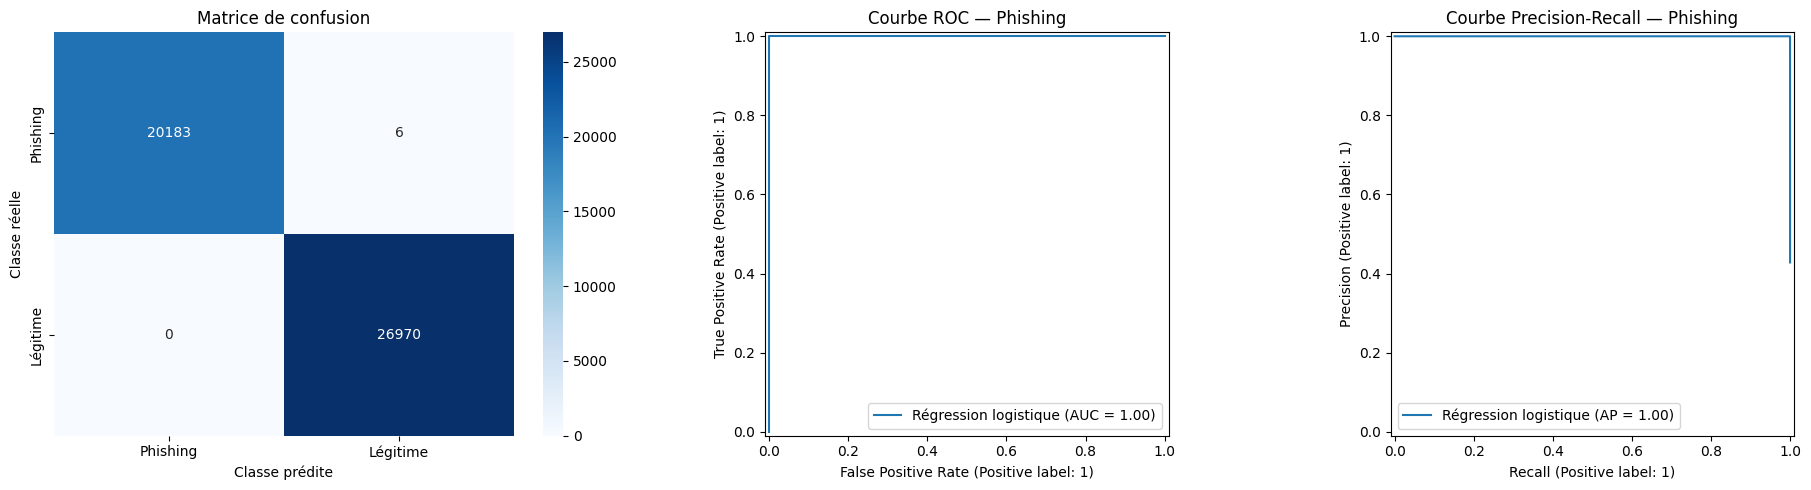

In [27]:

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay,
    precision_recall_curve
)

# Préparer les figures
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# 1. Matrice de confusion
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Phishing", "Légitime"],
    yticklabels=["Phishing", "Légitime"],
    ax=axes[0]
)

axes[0].set_title("Matrice de confusion")
axes[0].set_xlabel("Classe prédite")
axes[0].set_ylabel("Classe réelle")

# 2. Courbe ROC : phishing considéré comme classe positive
RocCurveDisplay.from_predictions(
    y_test_phishing,
    proba_phishing,
    name="Régression logistique",
    ax=axes[1]
)
axes[1].set_title("Courbe ROC — Phishing")

# 3. Courbe Precision-Recall
PrecisionRecallDisplay.from_predictions(
    y_test_phishing,
    proba_phishing,
    name="Régression logistique",
    ax=axes[2]
)
axes[2].set_title("Courbe Precision-Recall — Phishing")

plt.tight_layout()
plt.show()


In [28]:

# 1. Vérifier si certaines lignes sont identiques entre train et test
train_hash = pd.util.hash_pandas_object(
    x_train, index=False
)
test_hash = pd.util.hash_pandas_object(
    x_test, index=False
)

print(
    "Lignes identiques train/test :",
    test_hash.isin(train_hash).sum()
)

# 2. Corrélation des variables numériques avec la cible
correlations = (
    x_train
    .select_dtypes(include="number")
    .corrwith(y_train)
    .abs()
    .sort_values(ascending=False)
)

print("\nTop 15 des corrélations absolues :")
display(correlations.head(15))

# 3. Vérifier les colonnes qui distinguent presque
# parfaitement les deux classes
for col in correlations.head(10).index:
    print(f"\n{col}")
    display(
        x_train.groupby(y_train)[col]
        .agg(["min", "median", "mean", "max"])
    )


Lignes identiques train/test : 0

Top 15 des corrélations absolues :


,0
URLSimilarityIndex,0.860443
HasSocialNet,0.783682
HasCopyrightInfo,0.742820
HasDescription,0.690587
IsHTTPS,0.609105
DomainTitleMatchScore,0.583463
HasSubmitButton,0.578994
IsResponsive,0.548483
URLTitleMatchScore,0.538363
SpacialCharRatioInURL,0.533748



URLSimilarityIndex


,min,median,mean,max
label,,,,
0,0.155574,51.403306,49.588344,100.0
1,100.000000,100.000000,100.000000,100.0



HasSocialNet


...

,min,median,mean,max
label,,,,
0,0,0.0,0.317933,1
1,0,1.0,0.854616,1



URLTitleMatchScore


,min,median,mean,max
label,,,,
0,0.0,0.0,21.199329,100.0
1,0.0,100.0,75.166053,100.0



SpacialCharRatioInURL


,min,median,mean,max
label,,,,
0,0.005,0.080,0.083328,0.397
1,0.000,0.042,0.048399,0.231


In [30]:

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, precision_score, recall_score, f1_score
)
import pandas as pd

def creer_modele(colonnes_num):
    pipeline_numerique = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    pipeline_tld = Pipeline([
        ("encoder", OneHotEncoder(
            min_frequency=10,
            handle_unknown="infrequent_if_exist"
        ))
    ])

    preprocessor_local = ColumnTransformer([
        ("numerique", pipeline_numerique, colonnes_num),
        ("categoriel", pipeline_tld, ["TLD"])
    ])

    return Pipeline([
        ("preprocessing", preprocessor_local),
        ("classifier", LogisticRegression(
            max_iter=300,
            random_state=42
        ))
    ])

def evaluer_modele(nom, modele, xtr, xte):
    modele.fit(xtr, y_train)

    probabilites = modele.predict_proba(xte)
    indice_phishing = list(modele.classes_).index(0)
    proba_phishing = probabilites[:, indice_phishing]

    y_reel = (y_test == 0).astype(int)
    y_pred_phishing = (modele.predict(xte) == 0).astype(int)

    return {
        "Modèle": nom,
        "ROC-AUC": roc_auc_score(y_reel, proba_phishing),
        "Precision phishing": precision_score(
            y_reel, y_pred_phishing, zero_division=0
        ),
        "Recall phishing": recall_score(
            y_reel, y_pred_phishing, zero_division=0
        ),
        "F1 phishing": f1_score(
            y_reel, y_pred_phishing, zero_division=0
        )
    }

# A : toutes les variables
colonnes_num_a = x_train_model.select_dtypes(
    include="number"
).columns.tolist()

modele_a = creer_modele(colonnes_num_a)

resultats = [
    evaluer_modele(
        "Toutes les variables",
        modele_a,
        x_train_model,
        x_test_model
    )
]

# B : sans URLSimilarityIndex
x_train_b = x_train_model.drop(
    columns=["URLSimilarityIndex"], errors="ignore"
)
x_test_b = x_test_model.drop(
    columns=["URLSimilarityIndex"], errors="ignore"
)

colonnes_num_b = x_train_b.select_dtypes(
    include="number"
).columns.tolist()

modele_b = creer_modele(colonnes_num_b)

resultats.append(
    evaluer_modele(
        "Sans URLSimilarityIndex",
        modele_b,
        x_train_b,
        x_test_b
    )
)

tableau_resultats = pd.DataFrame(resultats)
display(tableau_resultats.round(4))


,Modèle,ROC-AUC,Precision phishing,Recall phishing,F1 phishing
0,Toutes les variables,1.0,1.0000,0.9997,0.9999
1,Sans URLSimilarityIndex,1.0,0.9994,0.9991,0.9992


In [31]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Variables du modèle, avec URLSimilarityIndex conservée
colonnes_a_exclure = ["URL", "Domain", "Title", "TLD_grouped"]

x_train_tree = x_train.drop(
    columns=colonnes_a_exclure,
    errors="ignore"
).copy()

x_test_tree = x_test.drop(
    columns=colonnes_a_exclure,
    errors="ignore"
).copy()

colonnes_numeriques_tree = x_train_tree.select_dtypes(
    include="number"
).columns.tolist()

preprocessor_tree = ColumnTransformer([
    ("numerique", SimpleImputer(strategy="median"),
     colonnes_numeriques_tree),
    ("categoriel", OneHotEncoder(
        min_frequency=10,
        handle_unknown="infrequent_if_exist"
    ), ["TLD"])
])

modele_dt = Pipeline([
    ("preprocessing", preprocessor_tree),
    ("classifier", DecisionTreeClassifier(
        max_depth=15,
        min_samples_leaf=5,
        random_state=42
    ))
])

modele_rf = Pipeline([
    ("preprocessing", preprocessor_tree),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

print("Les modèles sont prêts.")


Les modèles sont prêts.


In [32]:

from sklearn.metrics import (
    roc_auc_score, precision_score, recall_score, f1_score
)
import pandas as pd
import time

def evaluer_modele_simple(nom, modele, xtr, xte):
    debut = time.perf_counter()
    modele.fit(xtr, y_train)
    temps = time.perf_counter() - debut

    probabilites = modele.predict_proba(xte)
    indice_phishing = list(modele.classes_).index(0)
    proba_phishing = probabilites[:, indice_phishing]

    predictions = modele.predict(xte)
    y_reel = (y_test == 0).astype(int)
    y_pred_phishing = (predictions == 0).astype(int)

    return {
        "Modèle": nom,
        "ROC-AUC": roc_auc_score(y_reel, proba_phishing),
        "Precision phishing": precision_score(
            y_reel, y_pred_phishing, zero_division=0
        ),
        "Recall phishing": recall_score(
            y_reel, y_pred_phishing, zero_division=0
        ),
        "F1 phishing": f1_score(
            y_reel, y_pred_phishing, zero_division=0
        ),
        "Temps entraînement (s)": round(temps, 2)
    }

resultats_modeles = []

resultats_modeles.append(
    evaluer_modele_simple(
        "Decision Tree", modele_dt, x_train_tree, x_test_tree
    )
)

resultats_modeles.append(
    evaluer_modele_simple(
        "Random Forest", modele_rf, x_train_tree, x_test_tree
    )
)

comparaison = pd.DataFrame(resultats_modeles)
display(comparaison.round(4))


,Modèle,ROC-AUC,Precision phishing,Recall phishing,F1 phishing,Temps entraînement (s)
0,Decision Tree,1.0,1.0,1.0,1.0,8.69
1,Random Forest,1.0,1.0,1.0,1.0,38.66


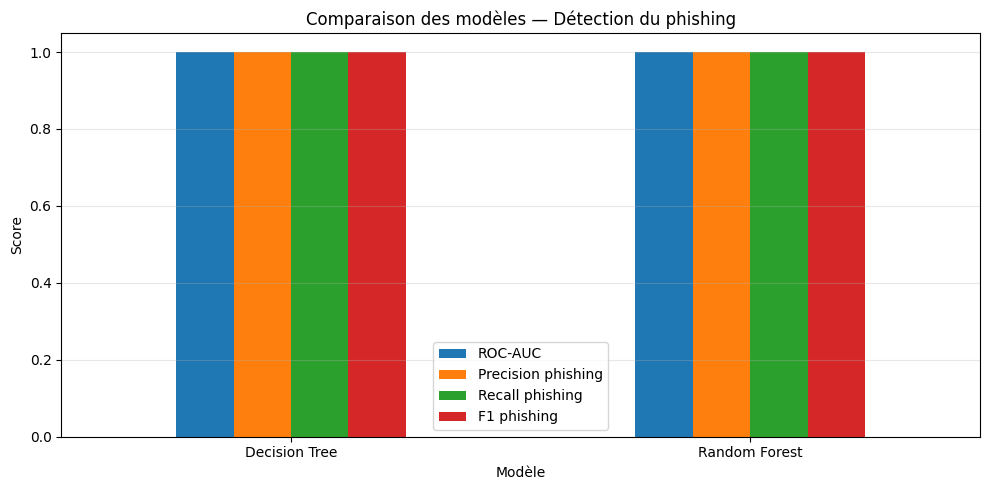

In [33]:

metriques = [
    "ROC-AUC",
    "Precision phishing",
    "Recall phishing",
    "F1 phishing"
]

comparaison.set_index("Modèle")[metriques].plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1.05),
    rot=0
)

plt.title("Comparaison des modèles — Détection du phishing")
plt.ylabel("Score")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [34]:

# Vérifier si URLSimilarityIndex sépare les classes
print("URLSimilarityIndex par classe :")

display(
    x_test.groupby(y_test)["URLSimilarityIndex"]
    .agg(["min", "median", "mean", "max", "nunique"])
)

# Vérifier si toutes les valeurs de la classe légitime valent 100
print(
    "\nPart des sites légitimes avec URLSimilarityIndex = 100 :",
    (
        x_test.loc[y_test == 1, "URLSimilarityIndex"] == 100
    ).mean()
)

# Vérifier si IsHTTPS sépare aussi les classes
print("\nIsHTTPS par classe :")

display(
    x_test.groupby(y_test)["IsHTTPS"]
    .agg(["min", "median", "mean", "max", "nunique"])
)


URLSimilarityIndex par classe :


,min,median,mean,max,nunique
label,,,,,
0,0.197141,51.564626,49.731485,100.0,11654
1,100.000000,100.000000,100.000000,100.0,1



Part des sites légitimes avec URLSimilarityIndex = 100 : 1.0

IsHTTPS par classe :


,min,median,mean,max,nunique
label,,,,,
0,0,0.0,0.4921,1,2
1,1,1.0,1.0000,1,1


In [35]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, roc_auc_score
import pandas as pd

variables_test = [
    "URLSimilarityIndex",
    "IsHTTPS",
    "HasSocialNet",
    "HasCopyrightInfo",
    "HasDescription",
    "DomainTitleMatchScore",
    "URLTitleMatchScore"
]

resultats_variables = []

for col in variables_test:
    # Un arbre simple utilisant une seule variable
    arbre = DecisionTreeClassifier(
        max_depth=3,
        random_state=42
    )

    arbre.fit(x_train[[col]], y_train)
    predictions = arbre.predict(x_test[[col]])
    probabilites = arbre.predict_proba(x_test[[col]])

    # Probabilité de la classe phishing (label 0)
    indice_phishing = list(arbre.classes_).index(0)
    proba_phishing = probabilites[:, indice_phishing]
    y_test_phishing = (y_test == 0).astype(int)

    resultats_variables.append({
        "Variable": col,
        "Accuracy": accuracy_score(y_test, predictions),
        "ROC-AUC phishing": roc_auc_score(
            y_test_phishing, proba_phishing
        )
    })

resultats_variables = pd.DataFrame(resultats_variables)
display(
    resultats_variables.sort_values(
        "ROC-AUC phishing", ascending=False
    ).round(4)
)


,Variable,Accuracy,ROC-AUC phishing
0,URLSimilarityIndex,0.9963,0.9957
2,HasSocialNet,0.8817,0.8960
3,HasCopyrightInfo,0.8665,0.8765
4,HasDescription,0.8299,0.8456
5,DomainTitleMatchScore,0.7939,0.8037
6,URLTitleMatchScore,0.7768,0.7867
1,IsHTTPS,0.7893,0.7540


In [37]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
import pandas as pd

experiences = {
    "Toutes les variables": x_train_model.columns.tolist(),
    "Sans URLSimilarityIndex": [
        col for col in x_train_model.columns
        if col != "URLSimilarityIndex"
    ],
    "URLSimilarityIndex seule": ["URLSimilarityIndex"]
}

resultats = []

for nom, colonnes in experiences.items():

    # Préparer les données de cette expérience
    xtr = x_train_model[colonnes].copy()
    xte = x_test_model[colonnes].copy()

    # Séparer les colonnes numériques et catégorielles
    colonnes_num = xtr.select_dtypes(include="number").columns.tolist()
    colonnes_cat = xtr.select_dtypes(exclude="number").columns.tolist()

    transformations = []

    if colonnes_num:
        pipeline_num = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ])
        transformations.append(("numerique", pipeline_num, colonnes_num))

    if colonnes_cat:
        from sklearn.preprocessing import OneHotEncoder

        pipeline_cat = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(
                min_frequency=10,
                handle_unknown="infrequent_if_exist"
            ))
        ])
        transformations.append(("categoriel", pipeline_cat, colonnes_cat))

    preprocesseur = ColumnTransformer(transformations)

    modele = Pipeline([
        ("preprocessing", preprocesseur),
        ("classifier", LogisticRegression(max_iter=300, random_state=42))
    ])

    modele.fit(xtr, y_train)

    probabilites = modele.predict_proba(xte)
    indice_phishing = list(modele.classes_).index(0)
    proba_phishing = probabilites[:, indice_phishing]

    y_test_phishing = (y_test == 0).astype(int)

    resultats.append({
        "Expérience": nom,
        "ROC-AUC phishing": roc_auc_score(
            y_test_phishing, proba_phishing
        )
    })

display(pd.DataFrame(resultats).round(5))

,Expérience,ROC-AUC phishing
0,Toutes les variables,1.00000
1,Sans URLSimilarityIndex,1.00000
2,URLSimilarityIndex seule,0.99567


In [38]:
from sklearn.metrics import confusion_matrix, classification_report
import pandas as pd

# Prédictions sur le jeu de test
y_pred = modele_lr.predict(x_test_model)

# Matrice de confusion : labels d'origine
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Matrice de confusion")
print("Ordre des classes : phishing (0), légitime (1)")
display(pd.DataFrame(
    cm,
    index=["Réel phishing", "Réel légitime"],
    columns=["Prédit phishing", "Prédit légitime"]
))

print("\nRapport de classification")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Phishing", "Légitime"],
    digits=6
))

# Nombre total d'erreurs
erreurs = (y_test != y_pred).sum()
print("Nombre total d'erreurs :", erreurs)

Matrice de confusion
Ordre des classes : phishing (0), légitime (1)


,Prédit phishing,Prédit légitime
Réel phishing,20183,6
Réel légitime,0,26970



Rapport de classification
              precision    recall  f1-score   support

    Phishing   1.000000  0.999703  0.999851     20189
    Légitime   0.999778  1.000000  0.999889     26970

    accuracy                       0.999873     47159
   macro avg   0.999889  0.999851  0.999870     47159
weighted avg   0.999873  0.999873  0.999873     47159

Nombre total d'erreurs : 6


In [39]:
from sklearn.metrics import accuracy_score, roc_auc_score
import pandas as pd

# Prédictions sur les deux ensembles
y_pred_train = modele_lr.predict(x_train_model)
y_pred_test = modele_lr.predict(x_test_model)

# Probabilités de la classe phishing (label = 0)
proba_train = modele_lr.predict_proba(x_train_model)
proba_test = modele_lr.predict_proba(x_test_model)

indice_phishing = list(modele_lr.classes_).index(0)

proba_train_phishing = proba_train[:, indice_phishing]
proba_test_phishing = proba_test[:, indice_phishing]

# Transformer les labels : 1 = phishing, 0 = légitime
y_train_phishing = (y_train == 0).astype(int)
y_test_phishing = (y_test == 0).astype(int)

# Comparer les performances
comparaison = pd.DataFrame({
    "Ensemble": ["Entraînement", "Test"],
    "Accuracy": [
        accuracy_score(y_train, y_pred_train),
        accuracy_score(y_test, y_pred_test)
    ],
    "ROC-AUC phishing": [
        roc_auc_score(y_train_phishing, proba_train_phishing),
        roc_auc_score(y_test_phishing, proba_test_phishing)
    ]
})

display(comparaison.round(6))

,Ensemble,Accuracy,ROC-AUC phishing
0,Entraînement,0.999894,0.999998
1,Test,0.999873,1.000000


In [40]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, roc_auc_score
import pandas as pd

resultats_regularisation = []

for c in [1.0, 0.1, 0.01, 0.001]:

    modele_test = Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("classifier", LogisticRegression(
            C=c,
            max_iter=500,
            random_state=42
        ))
    ])

    modele_test.fit(x_train_model, y_train)

    y_pred = modele_test.predict(x_test_model)
    probabilites = modele_test.predict_proba(x_test_model)

    indice_phishing = list(modele_test.classes_).index(0)
    proba_phishing = probabilites[:, indice_phishing]

    y_test_phishing = (y_test == 0).astype(int)

    resultats_regularisation.append({
        "C": c,
        "Accuracy": accuracy_score(y_test, y_pred),
        "ROC-AUC phishing": roc_auc_score(
            y_test_phishing, proba_phishing
        )
    })

display(pd.DataFrame(resultats_regularisation).round(6))

,C,Accuracy,ROC-AUC phishing
0,1.000,0.999873,1.000000
1,0.100,0.999873,1.000000
2,0.010,0.999597,1.000000
3,0.001,0.999173,0.999996


In [42]:
import pandas as pd
import numpy as np

# Récupérer le préprocesseur et le classifieur entraînés
preprocesseur_entraine = modele_lr.named_steps["preprocessing"]
classifieur = modele_lr.named_steps["classifier"]

# Récupérer les noms des variables après preprocessing
noms_variables = preprocesseur_entraine.get_feature_names_out()

# Les coefficients de la classe 1 correspondent à "légitime"
coefficients = classifieur.coef_[0]

importance = pd.DataFrame({
    "Variable": noms_variables,
    "Coefficient": coefficients,
    "Importance_absolue": np.abs(coefficients)
})

# Les 20 coefficients les plus importants en valeur absolue
importance = importance.sort_values(
    "Importance_absolue",
    ascending=False
)

display(importance.head(20).round(4))

,Variable,Coefficient,Importance_absolue
3,numerique__URLSimilarityIndex,6.9003,6.9003
21,numerique__IsHTTPS,3.8598,3.8598
20,numerique__SpacialCharRatioInURL,-1.8235,1.8235
13,numerique__LetterRatioInURL,-1.7178,1.7178
47,numerique__NoOfSelfRef,1.5563,1.5563
46,numerique__NoOfJS,1.5405,1.5405
36,numerique__HasSocialNet,1.4324,1.4324
49,numerique__NoOfExternalRef,1.3622,1.3622
8,numerique__NoOfSubDomain,1.2918,1.2918
44,numerique__NoOfImage,1.2830,1.2830


In [43]:
from sklearn.base import clone
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
import pandas as pd

variables_suspectes = [
    "URLSimilarityIndex",
    "IsHTTPS",
    "DomainTitleMatchScore"
]

colonnes_restantes = [
    col for col in x_train_model.columns
    if col not in variables_suspectes
]

experiences = {
    "Toutes les variables": x_train_model.columns.tolist(),
    "Sans URLSimilarityIndex": [
        col for col in x_train_model.columns
        if col != "URLSimilarityIndex"
    ],
    "Sans les 3 variables": colonnes_restantes
}

resultats = []

for nom, colonnes in experiences.items():
    xtr = x_train_model[colonnes]
    xte = x_test_model[colonnes]

    # Reconstruire un préprocesseur adapté aux colonnes conservées
    from sklearn.compose import ColumnTransformer
    from sklearn.impute import SimpleImputer
    from sklearn.preprocessing import StandardScaler, OneHotEncoder

    colonnes_num = xtr.select_dtypes(include="number").columns.tolist()
    colonnes_cat = xtr.select_dtypes(exclude="number").columns.tolist()

    transformations = []

    if colonnes_num:
        transformations.append((
            "numerique",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            colonnes_num
        ))

    if colonnes_cat:
        transformations.append((
            "categoriel",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(
                    min_frequency=10,
                    handle_unknown="infrequent_if_exist"
                ))
            ]),
            colonnes_cat
        ))

    preprocesseur = ColumnTransformer(transformations)

    modele = Pipeline([
        ("preprocessing", preprocesseur),
        ("classifier", LogisticRegression(
            max_iter=500,
            random_state=42
        ))
    ])

    modele.fit(xtr, y_train)

    predictions = modele.predict(xte)
    probabilites = modele.predict_proba(xte)
    indice_phishing = list(modele.classes_).index(0)

    y_test_phishing = (y_test == 0).astype(int)

    resultats.append({
        "Expérience": nom,
        "Accuracy": accuracy_score(y_test, predictions),
        "ROC-AUC phishing": roc_auc_score(
            y_test_phishing,
            probabilites[:, indice_phishing]
        )
    })

display(pd.DataFrame(resultats).round(6))

,Expérience,Accuracy,ROC-AUC phishing
0,Toutes les variables,0.999873,1.000000
1,Sans URLSimilarityIndex,0.999343,0.999996
2,Sans les 3 variables,0.997795,0.999934


In [44]:
print("Dimensions des données :", x.shape)

print("\nColonnes disponibles :")
print(x.columns.tolist())

print("\nRépartition des labels :")
print(y["label"].value_counts())

print("\nTypes des variables :")
print(x.dtypes.value_counts())

print("\nDescription du dataset :")
print(phiusiil_phishing_url_website.metadata)

Dimensions des données : (235795, 54)

Colonnes disponibles :
['URL', 'URLLength', 'Domain', 'DomainLength', 'IsDomainIP', 'TLD', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'Title', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef']

Répartition des labels :
label
1    134

In [45]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Colonnes brutes ou temporaires exclues du premier modèle
colonnes_a_supprimer = [
    "URL", "Domain", "Title", "TLD_grouped"
]

X_train = x_train.drop(
    columns=colonnes_a_supprimer, errors="ignore"
).copy()

X_test = x_test.drop(
    columns=colonnes_a_supprimer, errors="ignore"
).copy()

# Identifier les types de features
colonnes_categorielles = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

colonnes_numeriques = X_train.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

print("Nombre de features numériques :", len(colonnes_numeriques))
print("Nombre de features catégorielles :", len(colonnes_categorielles))
print("Total des features :", X_train.shape[1])

print("\nFeatures catégorielles :", colonnes_categorielles)

Nombre de features numériques : 50
Nombre de features catégorielles : 1
Total des features : 51

Features catégorielles : ['TLD']


In [46]:
def creer_preprocesseur(standardiser=False):

    pipeline_numerique = [
        ("imputer", SimpleImputer(strategy="median"))
    ]

    if standardiser:
        pipeline_numerique.append(
            ("scaler", StandardScaler())
        )

    transformateurs = [
        (
            "numerique",
            Pipeline(pipeline_numerique),
            colonnes_numeriques
        )
    ]

    if colonnes_categorielles:
        transformateurs.append(
            (
                "categoriel",
                Pipeline([
                    (
                        "imputer",
                        SimpleImputer(strategy="most_frequent")
                    ),
                    (
                        "encoder",
                        OneHotEncoder(
                            handle_unknown="infrequent_if_exist",
                            min_frequency=10
                        )
                    )
                ]),
                colonnes_categorielles
            )
        )

    return ColumnTransformer(transformateurs)


modeles = {
    "Logistic Regression": LogisticRegression(
        max_iter=500,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=15,
        min_samples_leaf=5,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
}

resultats = []
modeles_entraines = {}

for nom, classifieur in modeles.items():

    standardiser = nom == "Logistic Regression"

    pipeline = Pipeline([
        ("preprocessing", creer_preprocesseur(standardiser)),
        ("classifier", classifieur)
    ])

    debut = time.perf_counter()
    pipeline.fit(X_train, y_train)
    temps = time.perf_counter() - debut

    # Prédictions des classes originales : 0 = phishing
    predictions = pipeline.predict(X_test)

    # Récupérer la probabilité de phishing
    classes = list(pipeline.named_steps["classifier"].classes_)
    indice_phishing = classes.index(0)

    probabilites_phishing = pipeline.predict_proba(X_test)[
        :, indice_phishing
    ]

    # Métriques avec phishing comme classe positive
    y_test_phishing = (y_test == 0).astype(int)
    predictions_phishing = (predictions == 0).astype(int)

    resultats.append({
        "Modèle": nom,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision phishing": precision_score(
            y_test_phishing, predictions_phishing,
            zero_division=0
        ),
        "Recall phishing": recall_score(
            y_test_phishing, predictions_phishing,
            zero_division=0
        ),
        "F1 phishing": f1_score(
            y_test_phishing, predictions_phishing,
            zero_division=0
        ),
        "ROC-AUC phishing": roc_auc_score(
            y_test_phishing, probabilites_phishing
        ),
        "Temps entraînement (s)": temps
    })

    modeles_entraines[nom] = pipeline

tableau_resultats = pd.DataFrame(resultats)
display(
    tableau_resultats.sort_values(
        "F1 phishing", ascending=False
    ).round(4)
)

,Modèle,Accuracy,Precision phishing,Recall phishing,F1 phishing,ROC-AUC phishing,Temps entraînement (s)
1,Decision Tree,1.0000,1.0,1.0000,1.0000,1.0,4.8098
2,Random Forest,1.0000,1.0,1.0000,1.0000,1.0,36.3569
0,Logistic Regression,0.9999,1.0,0.9997,0.9999,1.0,8.0073


In [47]:
# Corrélation des variables numériques avec la cible
df_corr = X_train.copy()
df_corr["label"] = y_train

correlations = (
    df_corr
    .select_dtypes(include="number")
    .corr()["label"]
    .drop("label")
    .dropna()
    .sort_values(key=abs, ascending=False)
)

display(
    correlations.head(20).to_frame("Corrélation avec label")
)

,Corrélation avec label
URLSimilarityIndex,0.860443
HasSocialNet,0.783682
HasCopyrightInfo,0.742820
HasDescription,0.690587
IsHTTPS,0.609105
DomainTitleMatchScore,0.583463
HasSubmitButton,0.578994
IsResponsive,0.548483
URLTitleMatchScore,0.538363
SpacialCharRatioInURL,-0.533748


In [49]:
pip install -q xgboost imbalanced-learn

In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1 = phishing, 0 = legitimate
y_train_phish = (y_train == 0).astype(int)
y_test_phish = (y_test == 0).astype(int)

# A compact, interpretable initial feature set
features_candidates = [
    "URLSimilarityIndex",
    "URLLength",
    "DomainLength",
    "IsDomainIP",
    "NoOfSubDomain",
    "HasObfuscation",
    "NoOfObfuscatedChar",
    "LetterRatioInURL",
    "DegitRatioInURL",
    "SpacialCharRatioInURL",
    "CharContinuationRate",
    "TLDLegitimateProb",
    "IsHTTPS",
    "DomainTitleMatchScore",
    "URLTitleMatchScore",
    "HasTitle",
    "HasFavicon",
    "IsResponsive",
    "HasDescription",
    "HasSocialNet",
    "HasSubmitButton",
    "HasHiddenFields",
    "HasCopyrightInfo",
    "NoOfExternalRef",
    "NoOfSelfRef",
    "NoOfJS"
]
features_url_v2 = [
    "URLLength", "DomainLength", "IsDomainIP", "NoOfSubDomain", "TLDLength",
    "HasObfuscation", "ObfuscationRatio",
    "LetterRatioInURL", "DegitRatioInURL", "SpacialCharRatioInURL",
    "NoOfEqualsInURL", "NoOfQMarkInURL", "NoOfAmpersandInURL",
    "CharContinuationRate", "URLCharProb"
]
# Retain only columns that actually exist
features_selected = [
    f for f in features_candidates if f in x_train.columns
]
features_selected_v2 = [
    f for f in features_url_v2 if f in x_train.columns
]

print("Features candidates :", len(features_candidates))
print("Features disponibles :", len(features_selected))
print(features_selected)
print("Features disponibles v2 :", len(features_selected_v2))

print(features_selected_v2)

X_train_sel = x_train[features_selected].copy()
X_test_sel = x_test[features_selected].copy()

print("\nTrain :", X_train_sel.shape)
print("Test  :", X_test_sel.shape)

Features candidates : 26
Features disponibles : 26
['URLSimilarityIndex', 'URLLength', 'DomainLength', 'IsDomainIP', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'LetterRatioInURL', 'DegitRatioInURL', 'SpacialCharRatioInURL', 'CharContinuationRate', 'TLDLegitimateProb', 'IsHTTPS', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasTitle', 'HasFavicon', 'IsResponsive', 'HasDescription', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasCopyrightInfo', 'NoOfExternalRef', 'NoOfSelfRef', 'NoOfJS']
Features disponibles v2 : 15
['URLLength', 'DomainLength', 'IsDomainIP', 'NoOfSubDomain', 'TLDLength', 'HasObfuscation', 'ObfuscationRatio', 'LetterRatioInURL', 'DegitRatioInURL', 'SpacialCharRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'CharContinuationRate', 'URLCharProb']

Train : (188636, 26)
Test  : (47159, 26)


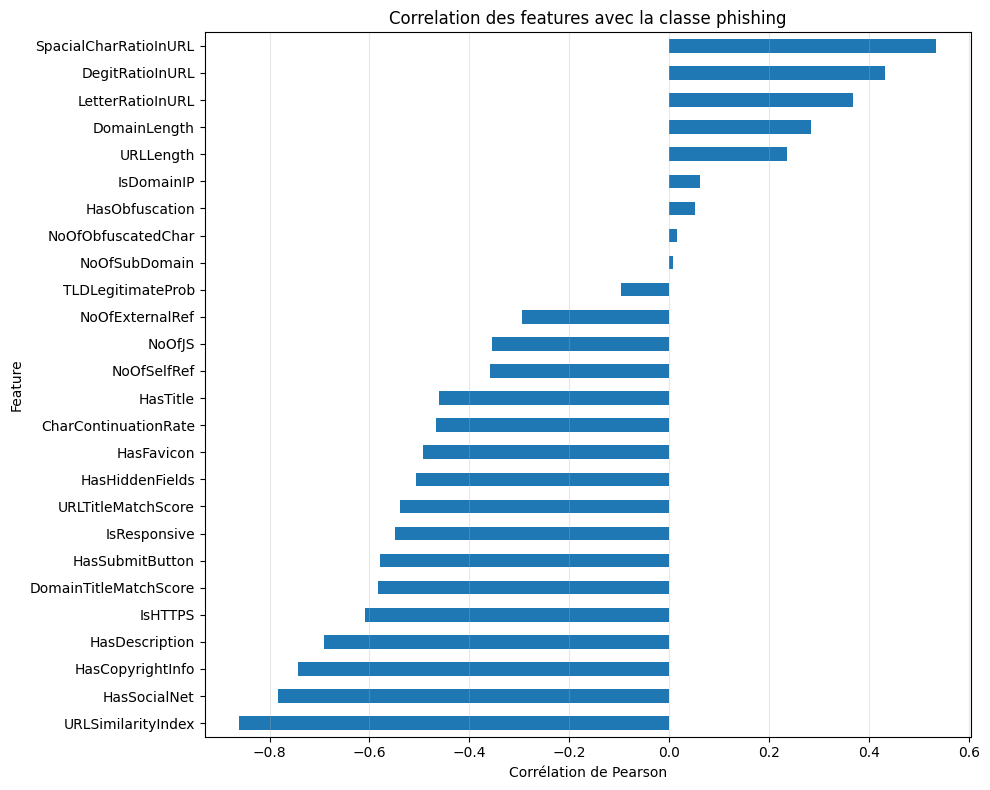

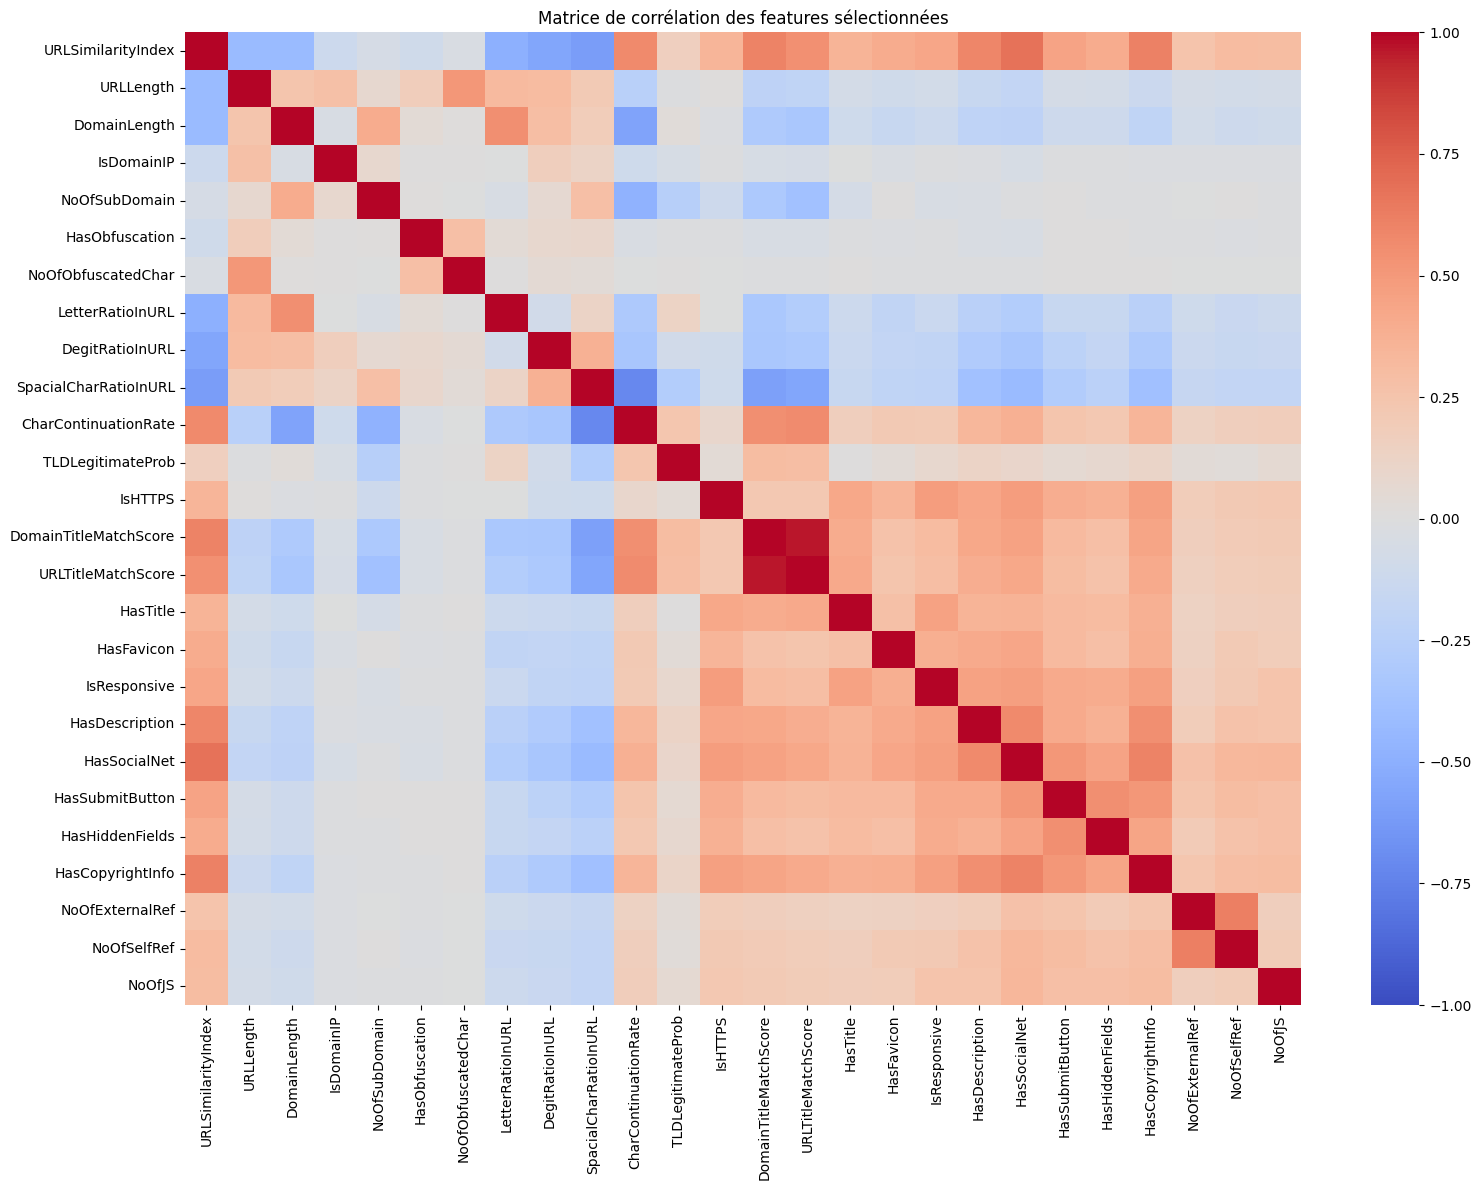

In [51]:
# Correlation of each numeric feature with phishing
df_corr = X_train_sel.copy()
df_corr["Phishing"] = y_train_phish

corr_target = (
    df_corr.select_dtypes(include="number")
    .corr()["Phishing"]
    .drop("Phishing")
    .dropna()
    .sort_values(key=abs, ascending=False)
)

plt.figure(figsize=(10, 8))
corr_target.sort_values().plot(kind="barh")
plt.title("Correlation des features avec la classe phishing")
plt.xlabel("Corrélation de Pearson")
plt.ylabel("Feature")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

# Correlation matrix between selected numeric features
corr_matrix = X_train_sel.select_dtypes(include="number").corr()

plt.figure(figsize=(16, 12))
sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)
plt.title("Matrice de corrélation des features sélectionnées")
plt.tight_layout()
plt.show()

In [52]:
import time

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)
from xgboost import XGBClassifier

# Same training subset for tuning all models
n_tune = min(20000, len(X_train_sel))

X_tune, _, y_tune, _ = train_test_split(
    X_train_sel,
    y_train_phish,
    train_size=n_tune,
    random_state=42,
    stratify=y_train_phish
)

configs = {
    "Logistic Regression": (
        LogisticRegression(max_iter=500, random_state=42),
        True,
        {
            "classifier__C": [0.1, 1.0],
            "classifier__class_weight": [None, "balanced"]
        }
    ),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=42),
        False,
        {
            "classifier__max_depth": [5, 10, 20],
            "classifier__min_samples_leaf": [2, 5]
        }
    ),
    "KNN": (
        KNeighborsClassifier(n_jobs=-1),
        True,
        {
            "classifier__n_neighbors": [5, 11],
            "classifier__weights": ["uniform", "distance"]
        }
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=42, n_jobs=-1),
        False,
        {
            "classifier__n_estimators": [100, 200],
            "classifier__max_depth": [10, 20],
            "classifier__min_samples_leaf": [2]
        }
    ),
    "XGBoost": (
        XGBClassifier(
            eval_metric="logloss",
            tree_method="hist",
            random_state=42,
            n_jobs=-1
        ),
        False,
        {
            "classifier__n_estimators": [100, 200],
            "classifier__max_depth": [3, 6],
            "classifier__learning_rate": [0.05, 0.1]
        }
    )
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

trained_models = {}
results = []

for name, (classifier, scale, grid) in configs.items():
    print(f"\nGrid Search : {name}")

    steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("scaler", StandardScaler()))

    pipeline = Pipeline([
        ("preprocessing", Pipeline(steps)),
        ("classifier", classifier)
    ])

    search = GridSearchCV(
        pipeline,
        param_grid=grid,
        scoring="f1",
        cv=cv,
        n_jobs=-1,
        refit=False,
        verbose=1
    )

    start = time.perf_counter()
    search.fit(X_tune, y_tune)
    grid_time = time.perf_counter() - start

    print("Best parameters:", search.best_params_)
    print("Best CV F1:", round(search.best_score_, 4))

    # Fit the best configuration on the full training set
    best_model = Pipeline([
        ("preprocessing", Pipeline(steps)),
        ("classifier", classifier)
    ]).set_params(**search.best_params_)

    start = time.perf_counter()
    best_model.fit(X_train_sel, y_train_phish)
    fit_time = time.perf_counter() - start

    trained_models[name] = best_model

    proba = best_model.predict_proba(X_test_sel)[:, 1]
    pred = (proba >= 0.5).astype(int)

    results.append({
        "Model": name,
        "CV F1": search.best_score_,
        "Accuracy": accuracy_score(y_test_phish, pred),
        "Precision phishing": precision_score(
            y_test_phish, pred, zero_division=0
        ),
        "Recall phishing": recall_score(
            y_test_phish, pred, zero_division=0
        ),
        "F1 phishing": f1_score(
            y_test_phish, pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test_phish, proba),
        "PR-AUC": average_precision_score(y_test_phish, proba),
        "Grid Search seconds": grid_time,
        "Fit seconds": fit_time
    })

results_df = pd.DataFrame(results).sort_values(
    "F1 phishing", ascending=False
)
display(results_df.round(4))


Grid Search : Logistic Regression
Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best parameters: {'classifier__C': 1.0, 'classifier__class_weight': None}
Best CV F1: 0.9998

Grid Search : Decision Tree
Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best parameters: {'classifier__max_depth': 5, 'classifier__min_samples_leaf': 2}
Best CV F1: 0.9999

Grid Search : KNN
Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best parameters: {'classifier__n_neighbors': 5, 'classifier__weights': 'distance'}
Best CV F1: 0.998

Grid Search : Random Forest
Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best parameters: {'classifier__max_depth': 10, 'classifier__min_samples_leaf': 2, 'classifier__n_estimators': 200}
Best CV F1: 1.0

Grid Search : XGBoost
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters: {'classifier__learning_rate': 0.05, 'classifier__max_depth': 3, 'classifier__n_estimators': 100}
Best CV F1: 0.9999


,Model,CV F1,Accuracy,Precision phishing,Recall phishing,F1 phishing,ROC-AUC,PR-AUC,Grid Search seconds,Fit seconds
3,Random Forest,1.0000,0.9999,1.0000,0.9998,0.9999,1.0000,1.0000,19.1629,42.6527
0,Logistic Regression,0.9998,0.9999,1.0000,0.9997,0.9999,1.0000,1.0000,8.8878,2.6218
4,XGBoost,0.9999,0.9999,1.0000,0.9997,0.9998,1.0000,1.0000,6.0638,4.0139
1,Decision Tree,0.9999,0.9998,1.0000,0.9997,0.9998,1.0000,1.0000,1.8099,1.8181
2,KNN,0.9980,0.9994,0.9998,0.9988,0.9993,0.9996,0.9995,9.1655,0.7712


In [54]:
# Si le résultat est 1, la variable ne dépend que du TLD :
# c'est une table de valeurs fixée par les auteurs, pas une mesure sur l'URL
print(x_train.groupby("TLD")["TLDLegitimateProb"].nunique().max())

1


In [57]:

print(features_selected_v2)

X_train_sel = x_train[features_selected_v2].copy()
X_test_sel = x_test[features_selected_v2].copy()

print("\nTrain :", X_train_sel.shape)
print("Test  :", X_test_sel.shape)

['URLLength', 'DomainLength', 'IsDomainIP', 'NoOfSubDomain', 'TLDLength', 'HasObfuscation', 'ObfuscationRatio', 'LetterRatioInURL', 'DegitRatioInURL', 'SpacialCharRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'CharContinuationRate', 'URLCharProb']

Train : (188636, 15)
Test  : (47159, 15)


In [58]:
#v2
import time

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)
from xgboost import XGBClassifier

# Same training subset for tuning all models
n_tune = min(20000, len(X_train_sel))

X_tune, _, y_tune, _ = train_test_split(
    X_train_sel,
    y_train_phish,
    train_size=n_tune,
    random_state=42,
    stratify=y_train_phish
)

configs = {
    "Logistic Regression": (
        LogisticRegression(max_iter=500, random_state=42),
        True,
        {
            "classifier__C": [0.1, 1.0],
            "classifier__class_weight": [None, "balanced"]
        }
    ),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=42),
        False,
        {
            "classifier__max_depth": [5, 10, 20],
            "classifier__min_samples_leaf": [2, 5]
        }
    ),
    "KNN": (
        KNeighborsClassifier(n_jobs=-1),
        True,
        {
            "classifier__n_neighbors": [5, 11],
            "classifier__weights": ["uniform", "distance"]
        }
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=42, n_jobs=-1),
        False,
        {
            "classifier__n_estimators": [100, 200],
            "classifier__max_depth": [10, 20],
            "classifier__min_samples_leaf": [2]
        }
    ),
    "XGBoost": (
        XGBClassifier(
            eval_metric="logloss",
            tree_method="hist",
            random_state=42,
            n_jobs=-1
        ),
        False,
        {
            "classifier__n_estimators": [100, 200],
            "classifier__max_depth": [3, 6],
            "classifier__learning_rate": [0.05, 0.1]
        }
    )
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

trained_models = {}
results = []

for name, (classifier, scale, grid) in configs.items():
    print(f"\nGrid Search : {name}")

    steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("scaler", StandardScaler()))

    pipeline = Pipeline([
        ("preprocessing", Pipeline(steps)),
        ("classifier", classifier)
    ])

    search = GridSearchCV(
        pipeline,
        param_grid=grid,
        scoring="f1",
        cv=cv,
        n_jobs=-1,
        refit=False,
        verbose=1
    )

    start = time.perf_counter()
    search.fit(X_tune, y_tune)
    grid_time = time.perf_counter() - start

    print("Best parameters:", search.best_params_)
    print("Best CV F1:", round(search.best_score_, 4))

    # Fit the best configuration on the full training set
    best_model = Pipeline([
        ("preprocessing", Pipeline(steps)),
        ("classifier", classifier)
    ]).set_params(**search.best_params_)

    start = time.perf_counter()
    best_model.fit(X_train_sel, y_train_phish)
    fit_time = time.perf_counter() - start

    trained_models[name] = best_model

    proba = best_model.predict_proba(X_test_sel)[:, 1]
    pred = (proba >= 0.5).astype(int)

    results.append({
        "Model": name,
        "CV F1": search.best_score_,
        "Accuracy": accuracy_score(y_test_phish, pred),
        "Precision phishing": precision_score(
            y_test_phish, pred, zero_division=0
        ),
        "Recall phishing": recall_score(
            y_test_phish, pred, zero_division=0
        ),
        "F1 phishing": f1_score(
            y_test_phish, pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test_phish, proba),
        "PR-AUC": average_precision_score(y_test_phish, proba),
        "Grid Search seconds": grid_time,
        "Fit seconds": fit_time
    })

results_df = pd.DataFrame(results).sort_values(
    "F1 phishing", ascending=False
)
display(results_df.round(4))


Grid Search : Logistic Regression
Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best parameters: {'classifier__C': 1.0, 'classifier__class_weight': 'balanced'}
Best CV F1: 0.8392

Grid Search : Decision Tree
Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best parameters: {'classifier__max_depth': 20, 'classifier__min_samples_leaf': 2}
Best CV F1: 0.9785

Grid Search : KNN
Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best parameters: {'classifier__n_neighbors': 5, 'classifier__weights': 'distance'}
Best CV F1: 0.937

Grid Search : Random Forest
Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best parameters: {'classifier__max_depth': 20, 'classifier__min_samples_leaf': 2, 'classifier__n_estimators': 200}
Best CV F1: 0.98

Grid Search : XGBoost
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters: {'classifier__learning_rate': 0.1, 'classifier__max_depth': 6, 'classifier__n_estimators': 200}
Best CV F1: 0.9909


,Model,CV F1,Accuracy,Precision phishing,Recall phishing,F1 phishing,ROC-AUC,PR-AUC,Grid Search seconds,Fit seconds
4,XGBoost,0.9909,0.9963,0.9983,0.9931,0.9957,0.9986,0.9989,8.7441,3.9677
3,Random Forest,0.9800,0.9948,0.9954,0.9924,0.9939,0.9984,0.9987,20.0041,57.0244
1,Decision Tree,0.9785,0.9937,0.9928,0.9925,0.9927,0.9951,0.9942,1.2684,1.6673
2,KNN,0.9370,0.9822,0.9857,0.9725,0.9791,0.9944,0.9922,26.9879,1.5698
0,Logistic Regression,0.8392,0.8734,0.9248,0.7666,0.8383,0.9162,0.9257,3.1981,1.9019


In [74]:
import time

knn = trained_models["KNN"]
petit = X_eval.sample(1000, random_state=42)

debut = time.perf_counter()
knn.predict_proba(petit)
t = time.perf_counter() - debut

print(f"1000 URLs : {t:.1f} secondes")
print(f"Estimation pour {len(X_eval)} URLs : {t * len(X_eval) / 1000 / 60:.1f} minutes")

1000 URLs : 5.9 secondes
Estimation pour 47159 URLs : 4.6 minutes


In [75]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    confusion_matrix, roc_curve, roc_auc_score,
    precision_recall_curve, average_precision_score,
    accuracy_score, precision_score, recall_score, f1_score
)

X_eval = x_test[features_url_v2]
y_eval = y_test_phish

SEUIL = 0.5   # tu le changeras quand tu auras choisi ton seuil

probas = {}
for nom in ["Logistic Regression", "Decision Tree", "Random Forest", "XGBoost"]:
    debut = time.perf_counter()
    probas[nom] = trained_models[nom].predict_proba(X_eval)[:, 1]
    print(nom, "terminé en", round(time.perf_counter() - debut, 1), "s")

Logistic Regression terminé en 0.0 s
Decision Tree terminé en 0.1 s
Random Forest terminé en 1.9 s
XGBoost terminé en 0.3 s


In [78]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    confusion_matrix, roc_curve, roc_auc_score,
    precision_recall_curve, average_precision_score,
    accuracy_score, precision_score, recall_score, f1_score
)

X_eval = x_test[features_url_v2]
y_eval = y_test_phish

SEUIL = 0.5   # tu le changeras quand tu auras choisi ton seuil

modeles_graphes = ["Logistic Regression", "Decision Tree", "Random Forest", "XGBoost"]

probas = {}
for nom in modeles_graphes:
    debut = time.perf_counter()
    probas[nom] = trained_models[nom].predict_proba(X_eval)[:, 1]
    print(nom, "terminé en", round(time.perf_counter() - debut, 1), "s")
    #print(nom, "proba :", probas[nom])


Logistic Regression terminé en 0.0 s
Logistic Regression proba : [0.13005666 0.37139353 0.11705146 ... 0.24804403 0.15024759 0.05340978]
Decision Tree terminé en 0.0 s
Decision Tree proba : [0.         0.         0.         ... 0.00295712 0.         0.        ]
Random Forest terminé en 1.6 s
Random Forest proba : [0.01975044 0.04194449 0.02076316 ... 0.03571893 0.02750712 0.01896739]
XGBoost terminé en 0.3 s
XGBoost proba : [0.00261305 0.00503205 0.00310738 ... 0.00370652 0.00264426 0.00262037]


In [76]:
knn = trained_models["KNN"]
morceaux = []
debut = time.perf_counter()

for i in range(0, len(X_eval), 5000):
    morceaux.append(knn.predict_proba(X_eval.iloc[i:i + 5000])[:, 1])
    fait = min(i + 5000, len(X_eval))
    print(f"{fait} / {len(X_eval)} URLs - {time.perf_counter() - debut:.0f} s")

probas["KNN"] = np.concatenate(morceaux)
print("KNN ajouté, durée totale :", round(time.perf_counter() - debut), "s")

5000 / 47159 URLs - 29 s
10000 / 47159 URLs - 44 s
15000 / 47159 URLs - 58 s
20000 / 47159 URLs - 71 s
25000 / 47159 URLs - 85 s
30000 / 47159 URLs - 99 s
35000 / 47159 URLs - 114 s
40000 / 47159 URLs - 144 s
45000 / 47159 URLs - 166 s
47159 / 47159 URLs - 171 s
KNN ajouté, durée totale : 171 s


In [80]:
probas["KNN"] = np.concatenate(morceaux)
print(list(probas.keys()))

['Logistic Regression', 'Decision Tree', 'Random Forest', 'XGBoost', 'KNN']


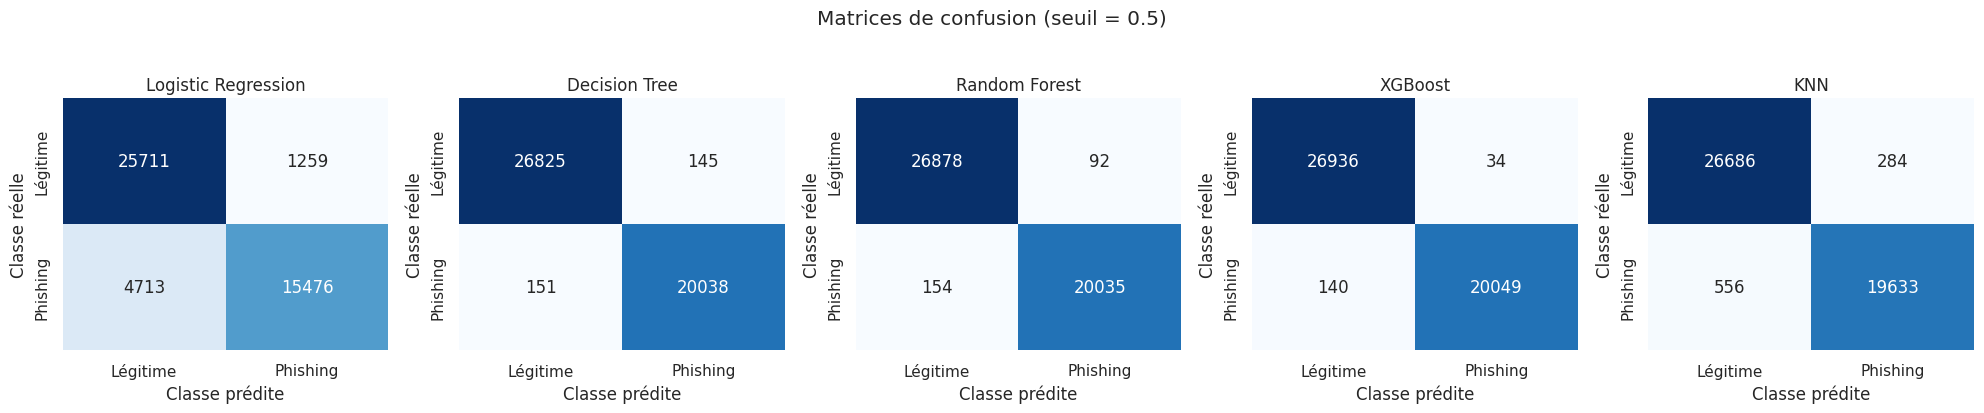

In [81]:
n = len(probas)
fig, axes = plt.subplots(1, n, figsize=(4 * n, 4))
axes = np.atleast_1d(axes)

for ax, (nom, p) in zip(axes, probas.items()):
    pred = (p >= SEUIL).astype(int)
    cm = confusion_matrix(y_eval, pred, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Légitime", "Phishing"],
                yticklabels=["Légitime", "Phishing"])
    ax.set_title(nom)
    ax.set_xlabel("Classe prédite")
    ax.set_ylabel("Classe réelle")

plt.suptitle(f"Matrices de confusion (seuil = {SEUIL})", y=1.03)
plt.tight_layout()
plt.show()

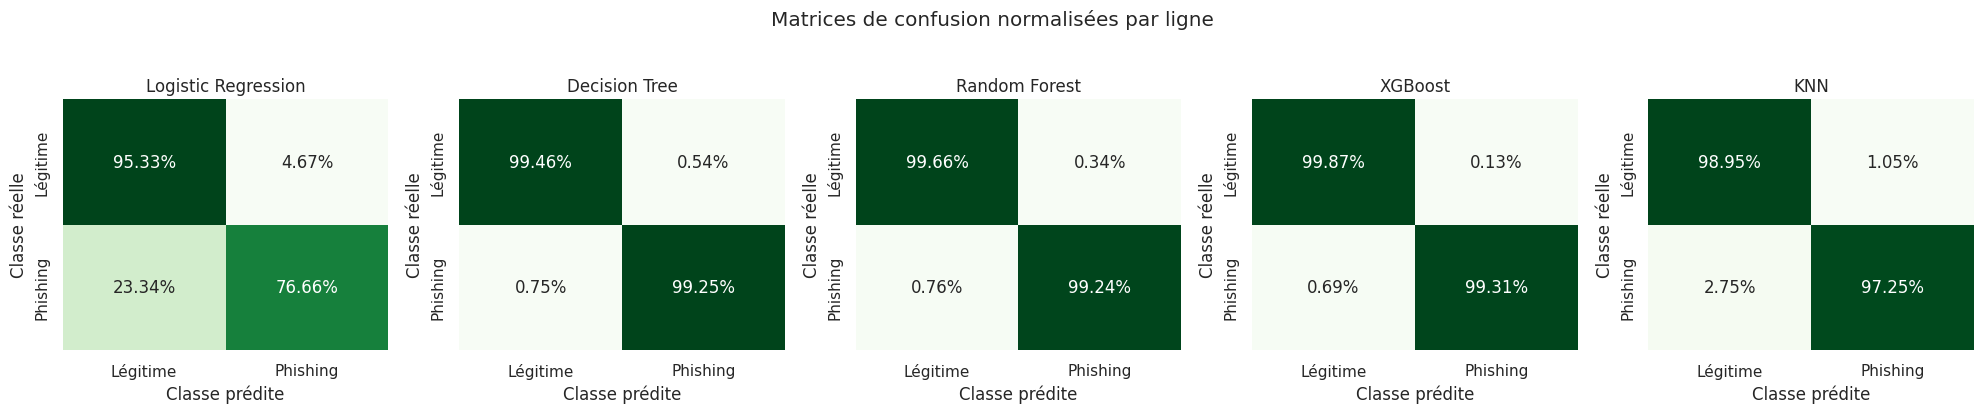

In [82]:
n = len(probas)
fig, axes = plt.subplots(1, n, figsize=(4 * n, 4))
axes = np.atleast_1d(axes)

for ax, (nom, p) in zip(axes, probas.items()):
    pred = (p >= SEUIL).astype(int)
    cm = confusion_matrix(y_eval, pred, labels=[0, 1], normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2%", cmap="Greens", cbar=False, ax=ax,
                xticklabels=["Légitime", "Phishing"],
                yticklabels=["Légitime", "Phishing"])
    ax.set_title(nom)
    ax.set_xlabel("Classe prédite")
    ax.set_ylabel("Classe réelle")

plt.suptitle("Matrices de confusion normalisées par ligne", y=1.03)
plt.tight_layout()
plt.show()

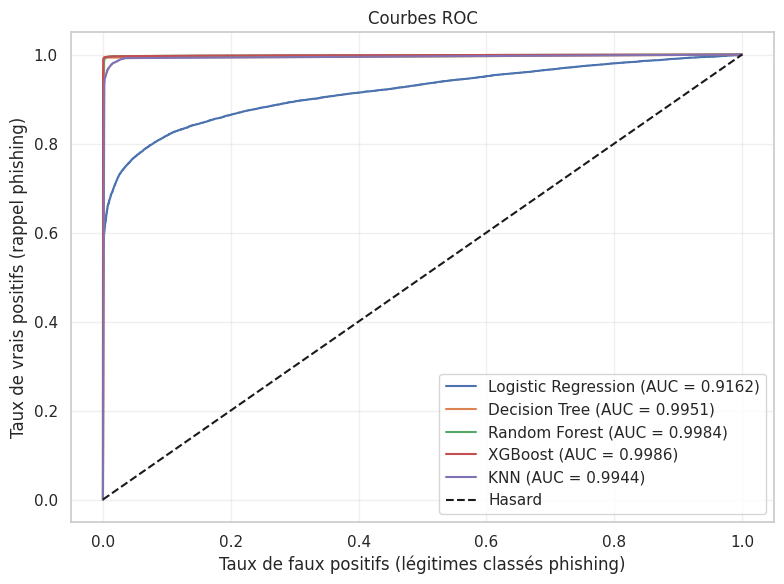

In [83]:
plt.figure(figsize=(8, 6))
for nom, p in probas.items():
    fpr, tpr, _ = roc_curve(y_eval, p)
    auc = roc_auc_score(y_eval, p)
    plt.plot(fpr, tpr, label=f"{nom} (AUC = {auc:.4f})")

plt.plot([0, 1], [0, 1], "k--", label="Hasard")
plt.xlabel("Taux de faux positifs (légitimes classés phishing)")
plt.ylabel("Taux de vrais positifs (rappel phishing)")
plt.title("Courbes ROC")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

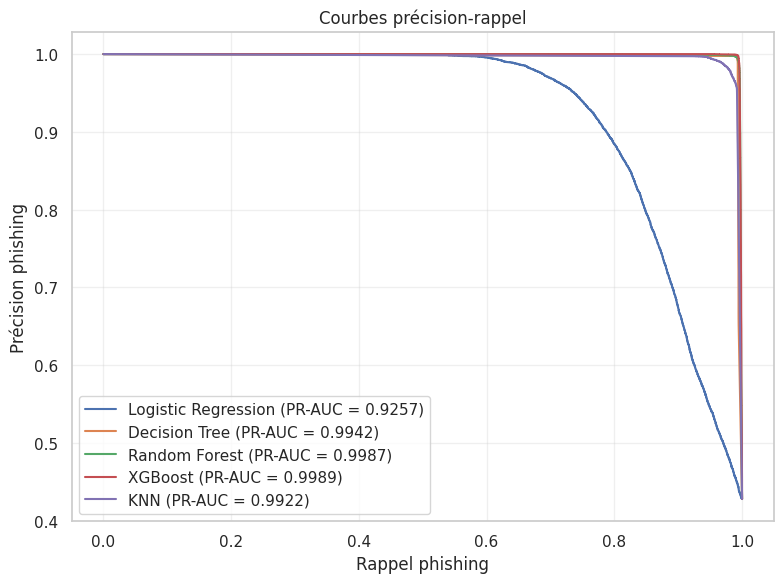

In [84]:
plt.figure(figsize=(8, 6))
for nom, p in probas.items():
    prec, rap, _ = precision_recall_curve(y_eval, p)
    ap = average_precision_score(y_eval, p)
    plt.plot(rap, prec, label=f"{nom} (PR-AUC = {ap:.4f})")

plt.xlabel("Rappel phishing")
plt.ylabel("Précision phishing")
plt.title("Courbes précision-rappel")
plt.legend(loc="lower left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

,Accuracy,Précision,Rappel,F1,ROC-AUC,PR-AUC
Modèle,,,,,,
Logistic Regression,0.8734,0.9248,0.7666,0.8383,0.9162,0.9257
Decision Tree,0.9937,0.9928,0.9925,0.9927,0.9951,0.9942
Random Forest,0.9948,0.9954,0.9924,0.9939,0.9984,0.9987
XGBoost,0.9963,0.9983,0.9931,0.9957,0.9986,0.9989
KNN,0.9822,0.9857,0.9725,0.9791,0.9944,0.9922


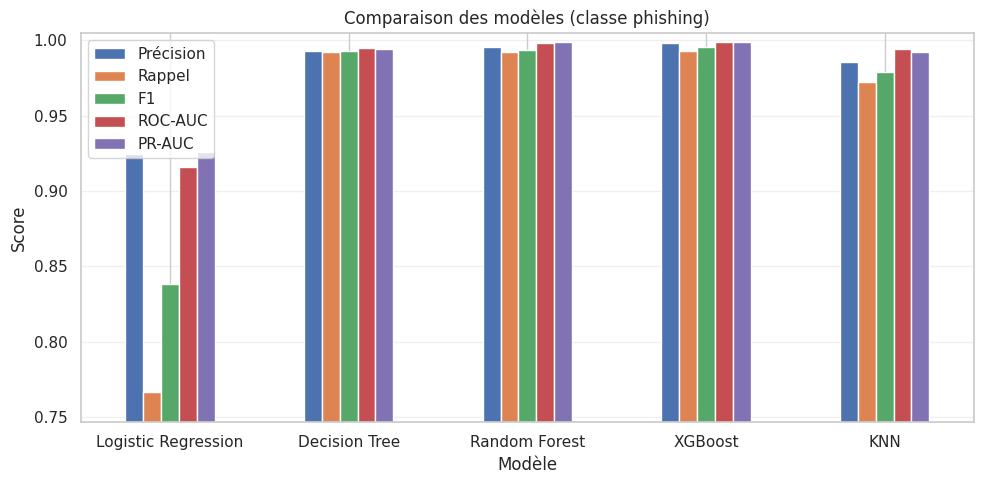

In [85]:
lignes = []
for nom, p in probas.items():
    pred = (p >= SEUIL).astype(int)
    lignes.append({
        "Modèle": nom,
        "Accuracy": accuracy_score(y_eval, pred),
        "Précision": precision_score(y_eval, pred, zero_division=0),
        "Rappel": recall_score(y_eval, pred, zero_division=0),
        "F1": f1_score(y_eval, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_eval, p),
        "PR-AUC": average_precision_score(y_eval, p),
    })

tableau = pd.DataFrame(lignes).set_index("Modèle")
display(tableau.round(4))

cols = ["Précision", "Rappel", "F1", "ROC-AUC", "PR-AUC"]
tableau[cols].plot(kind="bar", figsize=(10, 5), rot=0)
plt.ylim(max(0, tableau[cols].min().min() - 0.02), 1.005)
plt.title("Comparaison des modèles (classe phishing)")
plt.ylabel("Score")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

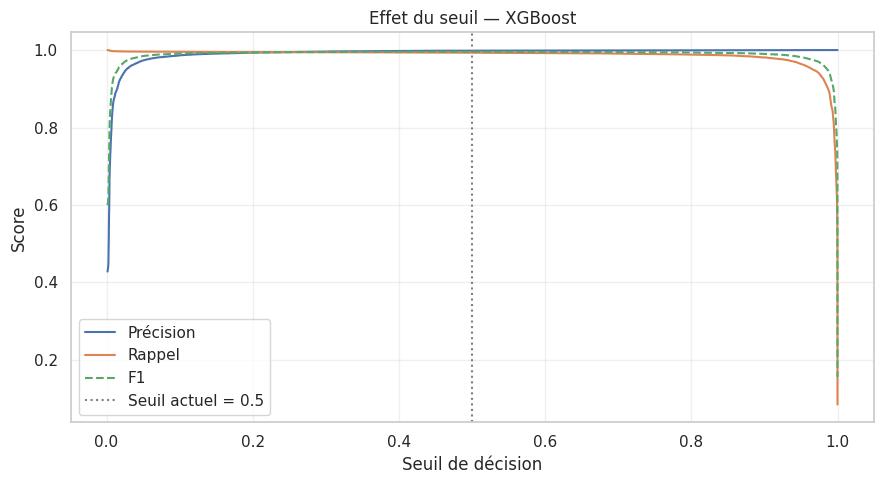

In [86]:
nom_choisi = tableau["F1"].idxmax()     # ou écris directement "XGBoost"
p = probas[nom_choisi]

precision, rappel, seuils = precision_recall_curve(y_eval, p)
precision, rappel = precision[:-1], rappel[:-1]
f1 = 2 * precision * rappel / (precision + rappel + 1e-12)

plt.figure(figsize=(9, 5))
plt.plot(seuils, precision, label="Précision")
plt.plot(seuils, rappel, label="Rappel")
plt.plot(seuils, f1, label="F1", linestyle="--")
plt.axvline(SEUIL, color="gray", linestyle=":", label=f"Seuil actuel = {SEUIL}")
plt.xlabel("Seuil de décision")
plt.ylabel("Score")
plt.title(f"Effet du seuil — {nom_choisi}")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

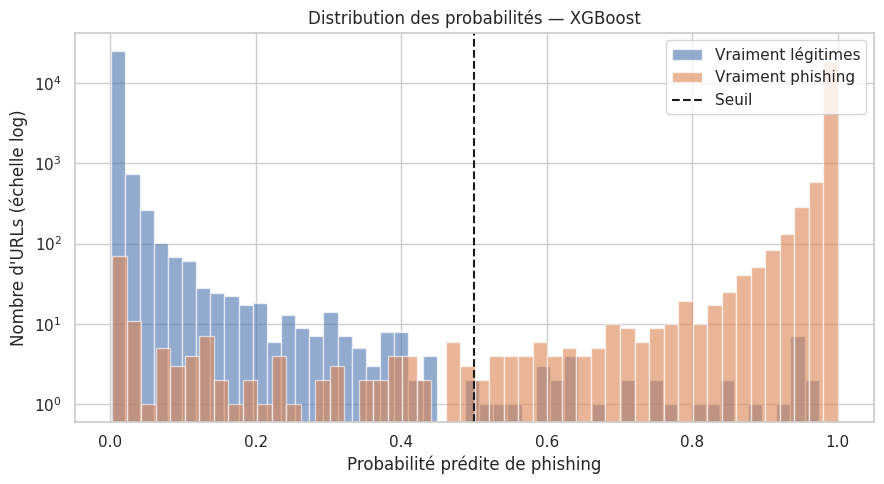

In [87]:
plt.figure(figsize=(9, 5))
plt.hist(p[y_eval == 0], bins=50, alpha=0.6, label="Vraiment légitimes")
plt.hist(p[y_eval == 1], bins=50, alpha=0.6, label="Vraiment phishing")
plt.axvline(SEUIL, color="k", linestyle="--", label="Seuil")
plt.yscale("log")
plt.xlabel("Probabilité prédite de phishing")
plt.ylabel("Nombre d'URLs (échelle log)")
plt.title(f"Distribution des probabilités — {nom_choisi}")
plt.legend()
plt.tight_layout()
plt.show()

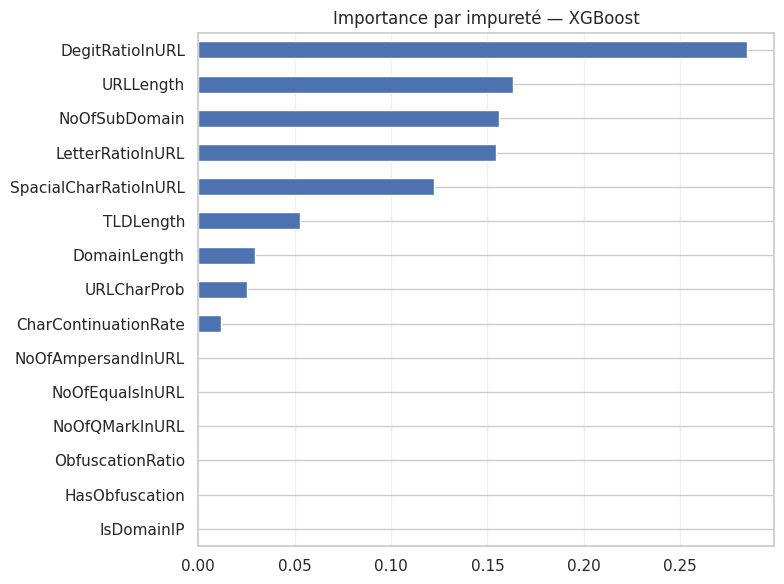

In [88]:
modele = trained_models[nom_choisi]
clf = modele.named_steps["classifier"]
noms_vars = list(X_eval.columns)

if hasattr(clf, "feature_importances_"):
    valeurs = clf.feature_importances_
    titre = "Importance par impureté"
elif hasattr(clf, "coef_"):
    valeurs = clf.coef_[0]
    titre = "Coefficients (variables standardisées)"
else:
    valeurs, titre = None, None
    print("Ce modèle (ex. KNN) n'a pas d'importance native.")

if valeurs is not None and len(valeurs) == len(noms_vars):
    imp = pd.Series(valeurs, index=noms_vars).sort_values(key=abs)
    imp.tail(15).plot(kind="barh", figsize=(8, 6))
    plt.title(f"{titre} — {nom_choisi}")
    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()

XGBoost terminé
Random Forest terminé
Logistic Regression terminé


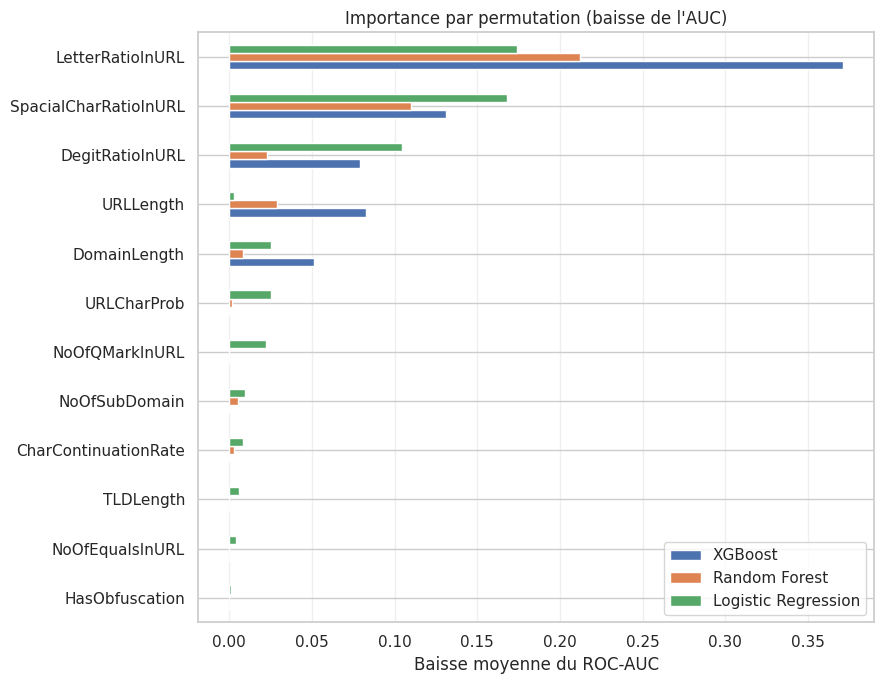

In [89]:
from sklearn.inspection import permutation_importance

idx = np.random.RandomState(42).choice(len(X_eval), size=3000, replace=False)
Xs = X_eval.iloc[idx]
ys = y_eval.iloc[idx]

modeles_perm = ["XGBoost", "Random Forest", "Logistic Regression"]

resultats_perm = {}
for nom in modeles_perm:
    r = permutation_importance(
        trained_models[nom], Xs, ys,
        scoring="roc_auc", n_repeats=3, random_state=42, n_jobs=-1
    )
    resultats_perm[nom] = pd.Series(r.importances_mean, index=Xs.columns)
    print(nom, "terminé")

perm_df = pd.DataFrame(resultats_perm)
ordre = perm_df.mean(axis=1).sort_values(ascending=False).head(12).index
perm_df.loc[ordre][::-1].plot(kind="barh", figsize=(9, 7))
plt.title("Importance par permutation (baisse de l'AUC)")
plt.xlabel("Baisse moyenne du ROC-AUC")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [62]:
import seaborn as sns

sns.set_theme(style="whitegrid")

df_all = x_train.copy()
df_all["phishing"] = y_train_phish.values
df_all["Classe"] = df_all["phishing"].map({0: "Légitime", 1: "Phishing"})

ech = df_all.sample(30000, random_state=42)
ORDRE = ["Légitime", "Phishing"]
COULEURS = {"Légitime": "#4C9F70", "Phishing": "#D1495B"}

print("Prêt :", df_all.shape, ech.shape)

Prêt : (188636, 57) (30000, 57)


/tmp/ipykernel_1221/288025842.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df_all, x="Classe", order=ORDRE, palette=COULEURS)


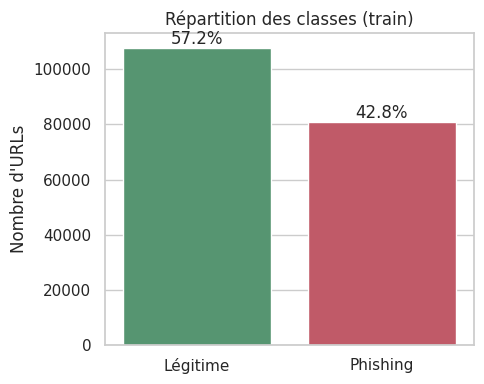

In [63]:
plt.figure(figsize=(5, 4))
ax = sns.countplot(data=df_all, x="Classe", order=ORDRE, palette=COULEURS)

for p in ax.patches:
    part = p.get_height() / len(df_all)
    ax.annotate(f"{part:.1%}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")

plt.title("Répartition des classes (train)")
plt.ylabel("Nombre d'URLs")
plt.xlabel("")
plt.tight_layout()
plt.show()

/tmp/ipykernel_1221/342166789.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=ech, x="Classe", y=c, order=ORDRE,
/tmp/ipykernel_1221/342166789.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=ech, x="Classe", y=c, order=ORDRE,
/tmp/ipykernel_1221/342166789.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=ech, x="Classe", y=c, order=ORDRE,
/tmp/ipykernel_1221/342166789.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set

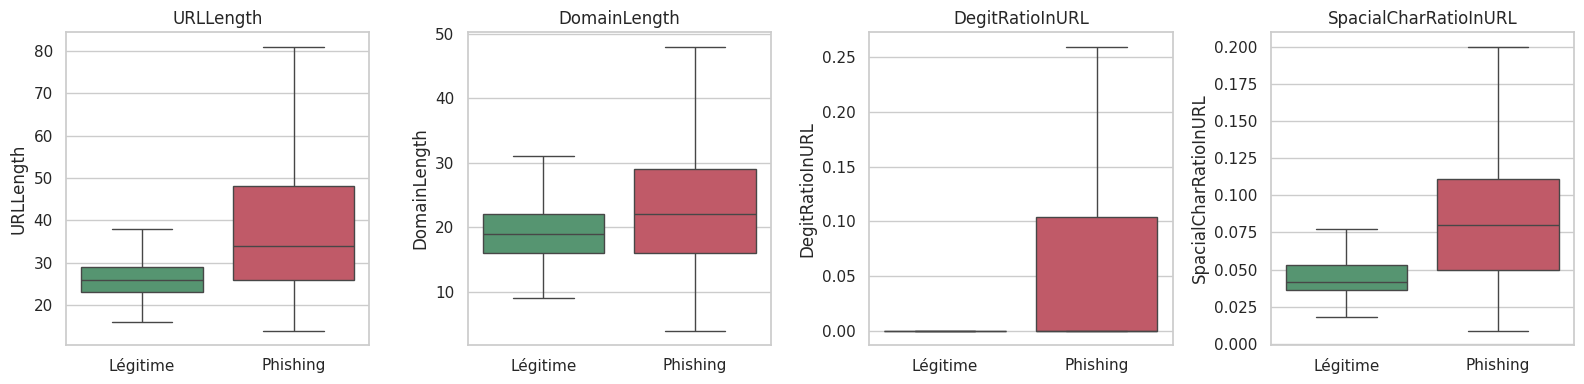

In [64]:
cols_box = ["URLLength", "DomainLength", "DegitRatioInURL", "SpacialCharRatioInURL"]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, c in zip(axes, cols_box):
    sns.boxplot(data=ech, x="Classe", y=c, order=ORDRE,
                palette=COULEURS, showfliers=False, ax=ax)
    ax.set_title(c)
    ax.set_xlabel("")

plt.tight_layout()
plt.show()

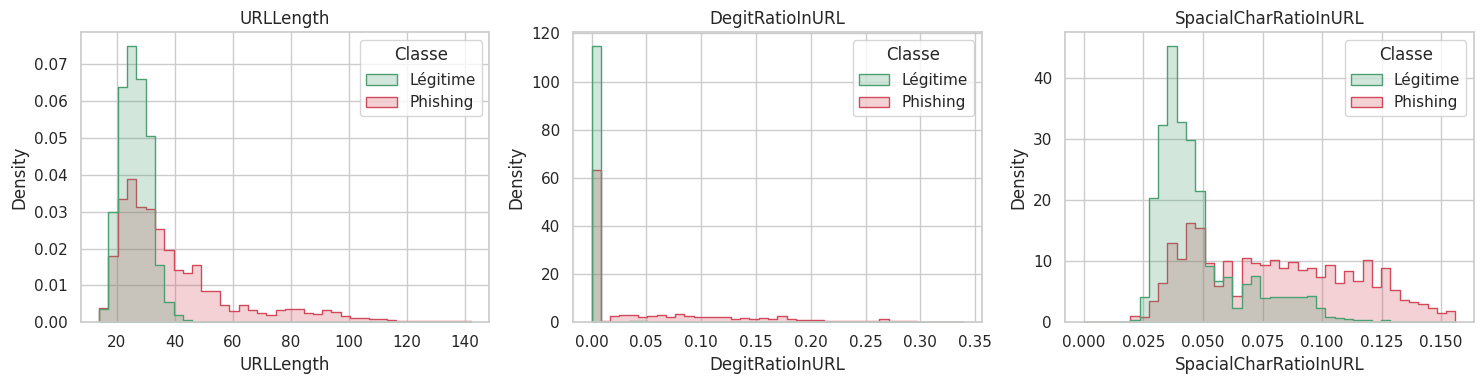

In [65]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, c in zip(axes, ["URLLength", "DegitRatioInURL", "SpacialCharRatioInURL"]):
    borne = ech[c].quantile(0.99)
    sns.histplot(data=ech[ech[c] <= borne], x=c, hue="Classe", hue_order=ORDRE,
                 palette=COULEURS, stat="density", common_norm=False,
                 element="step", bins=40, ax=ax)
    ax.set_title(c)

plt.tight_layout()
plt.show()

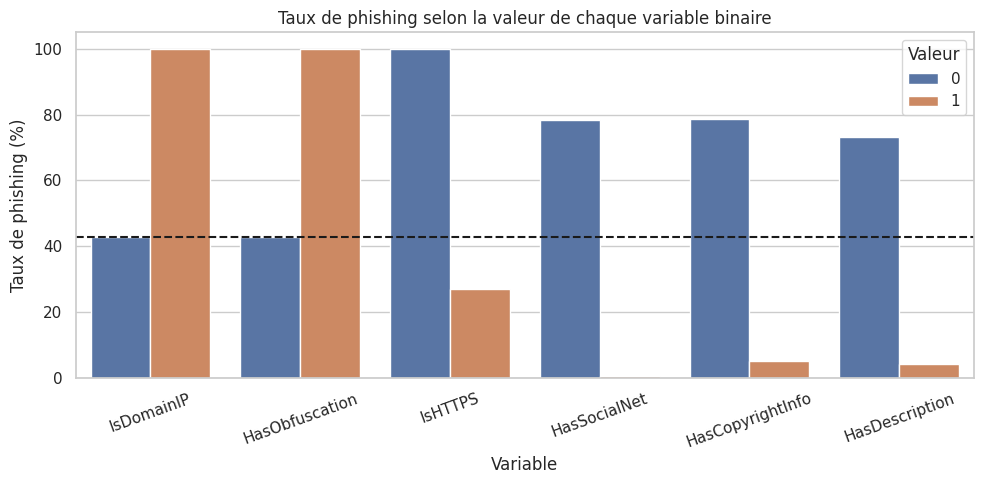

In [66]:
bin_vars = ["IsDomainIP", "HasObfuscation", "IsHTTPS",
            "HasSocialNet", "HasCopyrightInfo", "HasDescription"]

lignes = []
for v in bin_vars:
    for valeur, taux in (df_all.groupby(v)["phishing"].mean() * 100).items():
        lignes.append({"Variable": v, "Valeur": int(valeur),
                       "Taux de phishing (%)": taux})
tab = pd.DataFrame(lignes)

plt.figure(figsize=(10, 5))
sns.barplot(data=tab, x="Variable", y="Taux de phishing (%)", hue="Valeur")
plt.axhline(df_all["phishing"].mean() * 100, color="k", linestyle="--")
plt.xticks(rotation=20)
plt.title("Taux de phishing selon la valeur de chaque variable binaire")
plt.tight_layout()
plt.show()

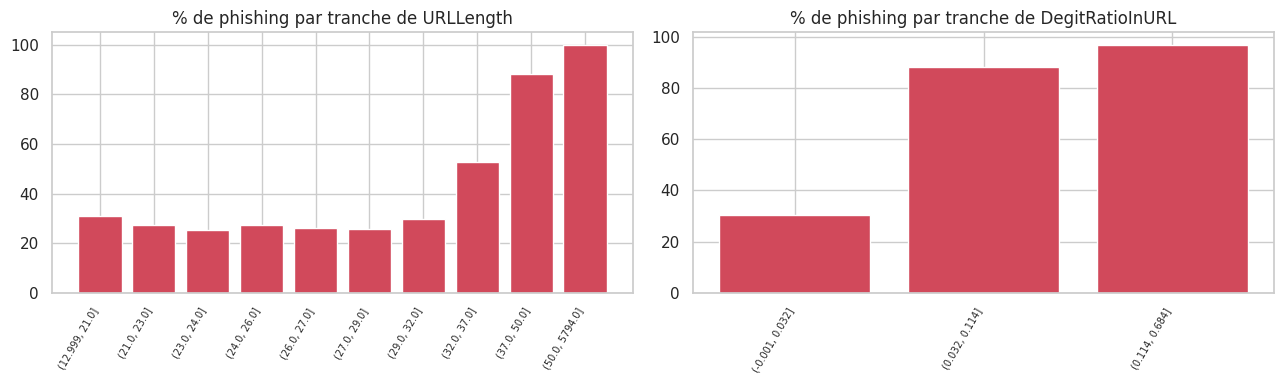

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, c in zip(axes, ["URLLength", "DegitRatioInURL"]):
    tranches = pd.qcut(df_all[c], q=10, duplicates="drop")
    t = df_all.groupby(tranches, observed=True)["phishing"].mean() * 100
    ax.bar(range(len(t)), t.values, color="#D1495B")
    ax.set_xticks(range(len(t)))
    ax.set_xticklabels([str(i) for i in t.index], rotation=60, ha="right", fontsize=7)
    ax.set_title(f"% de phishing par tranche de {c}")

plt.tight_layout()
plt.show()

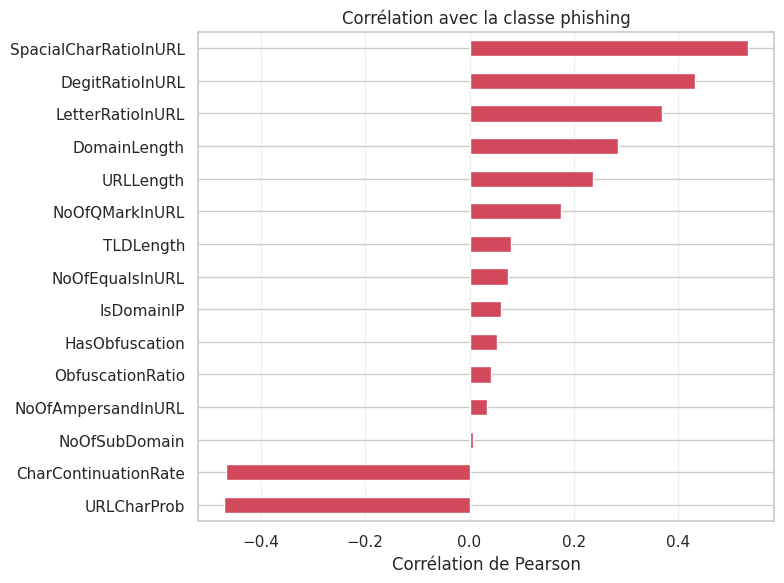

In [68]:
corr = (df_all[features_url_v2 + ["phishing"]]
        .corr()["phishing"].drop("phishing").sort_values())

corr.plot(kind="barh", figsize=(8, 6), color="#D1495B")
plt.title("Corrélation avec la classe phishing")
plt.xlabel("Corrélation de Pearson")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

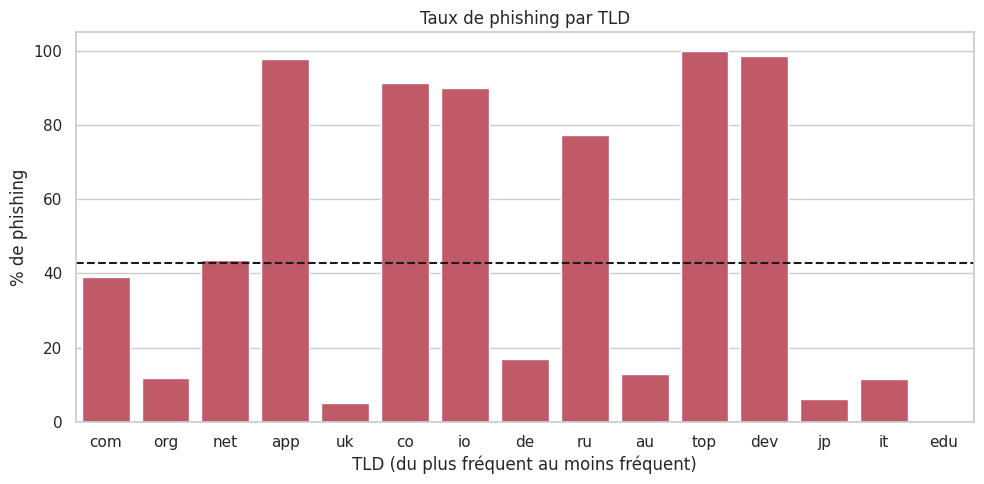

In [69]:
tld = df_all.groupby("TLD")["phishing"].agg(["mean", "size"])
tld = tld.sort_values("size", ascending=False).head(15)
tld["mean"] *= 100

plt.figure(figsize=(10, 5))
sns.barplot(x=tld.index, y=tld["mean"], color="#D1495B")
plt.axhline(df_all["phishing"].mean() * 100, color="k", linestyle="--")
plt.ylabel("% de phishing")
plt.xlabel("TLD (du plus fréquent au moins fréquent)")
plt.title("Taux de phishing par TLD")
plt.tight_layout()
plt.show()

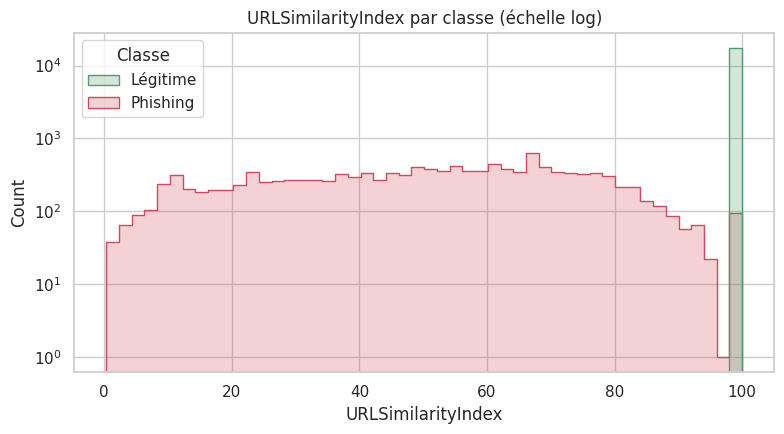

In [70]:
plt.figure(figsize=(8, 4.5))
sns.histplot(data=ech, x="URLSimilarityIndex", hue="Classe", hue_order=ORDRE,
             palette=COULEURS, bins=50, element="step")
plt.yscale("log")
plt.title("URLSimilarityIndex par classe (échelle log)")
plt.tight_layout()
plt.show()

In [91]:
pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 47.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 37.1 MB/s eta 0:00:00


In [94]:
import joblib, os, json

os.makedirs("projet", exist_ok=True)
joblib.dump(trained_models["XGBoost"], "projet/modele_xgboost.joblib")
json.dump(features_url_v2, open("projet/features.json", "w"))

print(round(os.path.getsize("projet/modele_xgboost.joblib") / 1e6, 2), "Mo")

0.69 Mo


In [95]:
import sklearn, xgboost, pandas, numpy, joblib

print("scikit-learn", sklearn.__version__)
print("xgboost", xgboost.__version__)
print("pandas", pandas.__version__)
print("numpy", numpy.__version__)
print("joblib", joblib.__version__)

scikit-learn 1.6.1
xgboost 3.4.1
pandas 2.2.3
numpy 2.1.3
joblib 1.6.0


In [97]:
from google.colab import files

files.download("projet/modele_xgboost.joblib")
files.download("projet/features.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>